## 0. Project setup
Create a repo with folders data/, notebooks/, src/, configs/, results/.
Make an environment with torch, torchaudio, transformers, datasets, librosa, scikit-learn, matplotlib, optuna.
Fix random seeds, and log package versions and every run’s settings (a config.yaml per run, plus Weights & Biases or MLflow if you like).
Start a manifest.csv that records every file’s source, label and split.

## 1. Data collection
Load DADS from [Z121mm/drone-audio-detection-samples](https://huggingface.co/datasets/Z121mm/drone-audio-detection-samples), a copy of `geronimobasso/drone-audio-detection-samples`.
Record each clip’s origin where you can (the dataset card lists the source datasets).
Add distractor data (ESC-50, UrbanSound8K, FSD50K subsets) and, later, your own recordings as a final test set.
Note each source’s license in the manifest.

In [3]:
from collections import Counter

try:
    from datasets import load_dataset
except ImportError:
    import subprocess
    import sys
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "datasets"])
    from datasets import load_dataset

ds = load_dataset("Z121mm/drone-audio-detection-samples")
train = ds["train"]
names = train.features["label"].names
counts = Counter(train["label"])
print(ds)
print("columns:", train.column_names)
print("label names:", names)
for index, name in enumerate(names):
    print(f"label {index} ({name}): {counts[index]:,} clips")


README.md:   0%|          | 0.00/4.05k [00:00<?, ?B/s]

Resolving data files:   0%|          | 0/39 [00:00<?, ?it/s]

Resolving data files:   0%|          | 0/39 [00:00<?, ?it/s]

data/train-00000-of-00039.parquet: reconstructing file:   0%|          |  0.00B / 1.27GB            

data/train-00000-of-00039.parquet: downloading bytes:           |  0.00B            

...

data/train-00037-of-00039.parquet: downloading bytes:           |  0.00B            

data/train-00038-of-00039.parquet: reconstructing file:   0%|          |  0.00B / 75.0MB            

data/train-00038-of-00039.parquet: downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/180320 [00:00<?, ? examples/s]

DatasetDict({
    train: Dataset({
        features: ['audio', 'label'],
        num_rows: 180320
    })
})
columns: ['audio', 'label']
label names: ['0', '1']
label 0 (0): 16,729 clips
label 1 (1): 163,591 clips


## 2.1 Exploratory data analysis
Count clips per class and per source, and plot clip-length histograms (lengths run from 0.02 s to 228 s).
Check sample rates and channels, and flag silent, clipped or corrupt files.
Plot average spectrograms for drone and non-drone, and listen to about 30 random clips per class.
Check for duplicates (audio hashes) and for shortcuts: can a simple model guess the source from the audio alone? If so, fix that before modeling.

Resolving data files:   0%|          | 0/39 [00:00<?, ?it/s]

Resolving data files:   0%|          | 0/39 [00:00<?, ?it/s]

,clips,hours,min s,median s,mean s,max s
class_name,,,,,,
No drone,"16,729",33.81,0.020,4.000,7.276,16.0
Drone,"163,591",27.10,0.500,0.500,0.596,315.8


Check,Count
Unreadable files,0
Sample rate other than 16 kHz,0
Not mono,0
Not 16-bit,0
Exact digital silence,0
Quieter than -60 dBFS,"1,056"
Clipped at full scale,"1,103"
Files that share an audio hash,30
Identical hashes with both labels,0


Duplicate groups: 15
Clips in the mean spectrum: no drone 16,541, drone 163,591
Filenames are drone-N.wav and no-drone-N.wav. The original corpus is not a column, so clips cannot be counted per source, and a model cannot be tested for guessing the source.


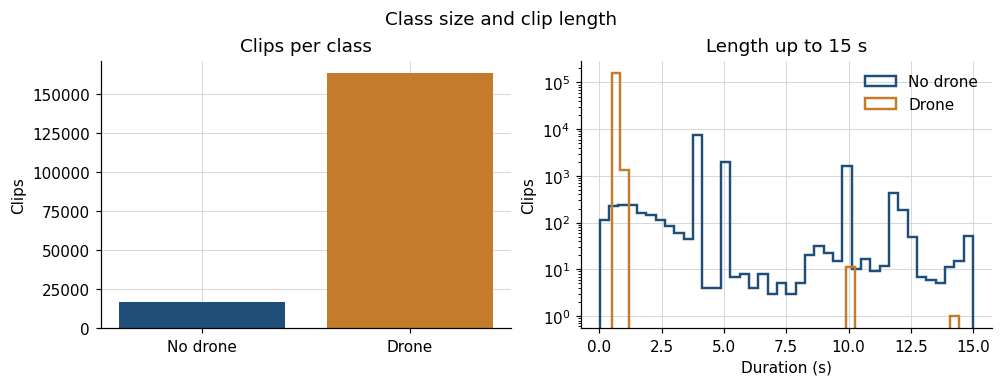

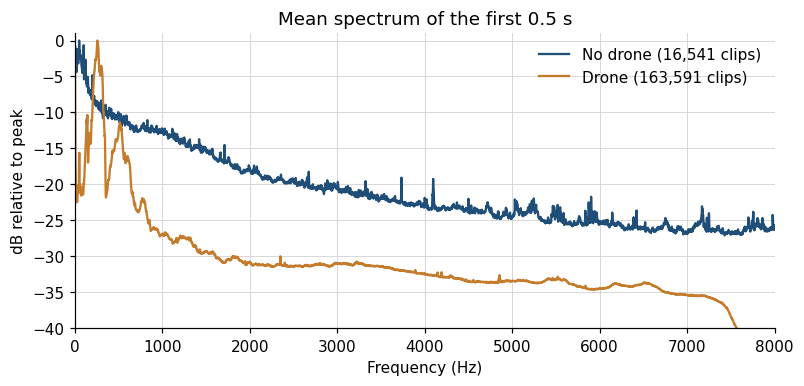

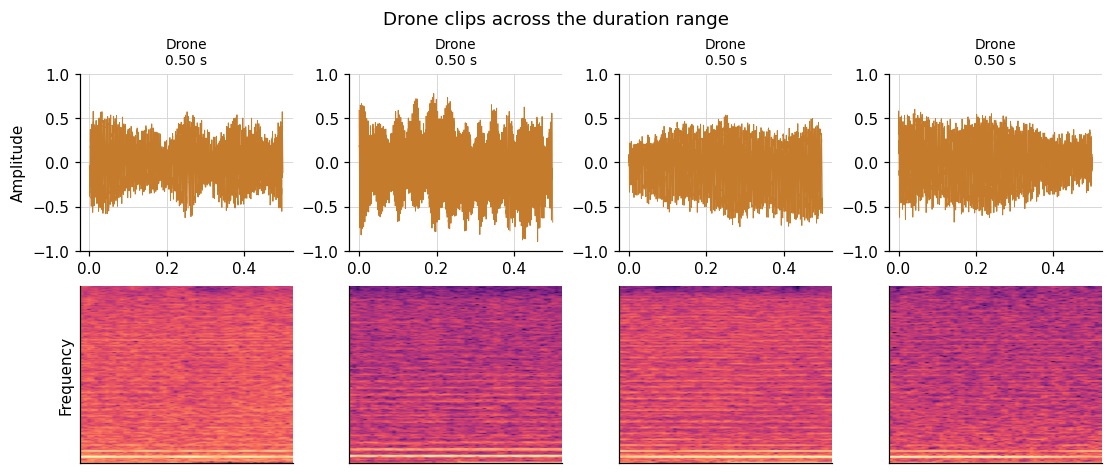

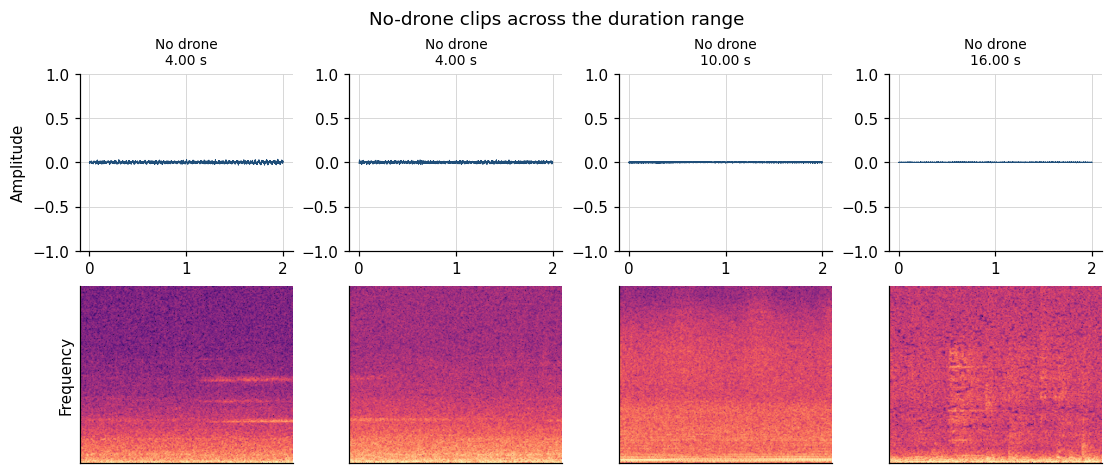

In [4]:
import hashlib
from io import BytesIO
import wave

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from datasets import Audio, load_dataset

plt.rcParams.update({
    "figure.dpi": 110,
    "figure.facecolor": "white",
    "axes.facecolor": "white",
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.color": "#d5d5d5",
    "grid.linewidth": 0.6,
    "axes.axisbelow": True,
    "font.size": 10,
    "axes.titlesize": 12,
    "legend.frameon": False,
})


def show(fig):
    display(fig)
    plt.close(fig)


train = load_dataset("Z121mm/drone-audio-detection-samples")["train"].cast_column("audio", Audio(decode=False))
LABEL = {0: "No drone", 1: "Drone"}
N = len(train)
SPECTRUM_SAMPLES = 8_000  # 0.5 s at 16 kHz
spectrum = np.zeros((2, SPECTRUM_SAMPLES // 2 + 1), dtype=np.float64)
spectrum_n = np.zeros(2, dtype=np.int64)
window = np.hanning(SPECTRUM_SAMPLES).astype(np.float32)

duration_s = np.empty(N, dtype=np.float32)
rms = np.empty(N, dtype=np.float32)
peak = np.empty(N, dtype=np.int32)
rate = np.empty(N, dtype=np.int32)
channels = np.empty(N, dtype=np.int16)
width = np.empty(N, dtype=np.int16)
label = np.empty(N, dtype=np.int8)
readable = np.ones(N, dtype=bool)
digests = []

for index, row in enumerate(train):
    label[index] = row["label"]
    blob = row["audio"]["bytes"]
    digests.append(hashlib.md5(blob).hexdigest())
    try:
        with wave.open(BytesIO(blob), "rb") as handle:
            channels[index] = handle.getnchannels()
            width[index] = handle.getsampwidth()
            rate[index] = handle.getframerate()
            frames = handle.getnframes()
            raw = handle.readframes(frames)
    except (wave.Error, EOFError):
        readable[index] = False
        duration_s[index] = np.nan
        rms[index] = np.nan
        peak[index] = -1
        channels[index] = 0
        width[index] = 0
        rate[index] = 0
        continue
    duration_s[index] = frames / rate[index] if rate[index] else np.nan
    if width[index] != 2 or not raw:
        rms[index] = np.nan
        peak[index] = -1
        continue
    samples = np.frombuffer(raw, dtype="<i2")
    peak[index] = int(np.max(np.abs(samples))) if samples.size else 0
    rms[index] = float(np.sqrt(np.mean(samples.astype(np.float32) ** 2))) if samples.size else 0.0
    if (
        channels[index] == 1
        and rate[index] == 16_000
        and samples.size >= SPECTRUM_SAMPLES
        and rms[index] > 0
    ):
        clip = samples[:SPECTRUM_SAMPLES].astype(np.float32) / np.float32(32768.0)
        power = np.abs(np.fft.rfft(clip * window)) ** 2
        total = power.sum()
        if total > 0:
            spectrum[label[index]] += power / total
            spectrum_n[label[index]] += 1

meta = pd.DataFrame({
    "label": label,
    "duration_s": duration_s,
    "rms": rms,
    "peak": peak,
    "rate": rate,
    "channels": channels,
    "width": width,
    "readable": readable,
    "md5": digests,
})
meta["class_name"] = meta.label.map(LABEL)
meta["rms_db"] = 20 * np.log10(np.maximum(meta.rms / 32768.0, 1e-12))
meta.loc[~meta.readable, "rms_db"] = np.nan

counts = meta.groupby("class_name", sort=False).size().rename("clips")
hours = meta.groupby("class_name", sort=False).duration_s.sum() / 3600
duration_table = meta.groupby("class_name", sort=False).duration_s.agg(["min", "median", "mean", "max"])
summary = duration_table.copy()
summary.insert(0, "clips", counts)
summary.insert(1, "hours", hours)
summary = summary.rename(columns={"min": "min s", "median": "median s", "mean": "mean s", "max": "max s"})
display(summary.style.format({
    "clips": "{:,}",
    "hours": "{:.2f}",
    "min s": "{:.3f}",
    "median s": "{:.3f}",
    "mean s": "{:.3f}",
    "max s": "{:.1f}",
}))

n_bad_rate = int((meta.readable & (meta.rate != 16_000)).sum())
n_bad_channels = int((meta.readable & (meta.channels != 1)).sum())
n_bad_width = int((meta.readable & (meta.width != 2)).sum())
n_unreadable = int((~meta.readable).sum())
n_silence = int((meta.readable & (meta.rms == 0)).sum())
n_quiet = int((meta.readable & (meta.rms_db < -60)).sum())
n_clipped = int((meta.peak >= 32767).sum())
hash_counts = meta.md5.value_counts()
n_duplicate_groups = int((hash_counts > 1).sum())
n_duplicate_files = int(hash_counts[hash_counts > 1].sum())
cross_label = int(meta.groupby("md5").label.nunique().gt(1).sum())

checks = pd.DataFrame([
    {"Check": "Unreadable files", "Count": n_unreadable},
    {"Check": "Sample rate other than 16 kHz", "Count": n_bad_rate},
    {"Check": "Not mono", "Count": n_bad_channels},
    {"Check": "Not 16-bit", "Count": n_bad_width},
    {"Check": "Exact digital silence", "Count": n_silence},
    {"Check": "Quieter than -60 dBFS", "Count": n_quiet},
    {"Check": "Clipped at full scale", "Count": n_clipped},
    {"Check": "Files that share an audio hash", "Count": n_duplicate_files},
    {"Check": "Identical hashes with both labels", "Count": cross_label},
])
display(checks.style.format({"Count": "{:,}"}).hide(axis="index"))
print(f"Duplicate groups: {n_duplicate_groups:,}")
print(f"Clips in the mean spectrum: no drone {spectrum_n[0]:,}, drone {spectrum_n[1]:,}")
print("Filenames are drone-N.wav and no-drone-N.wav. The original corpus is not a column, so clips cannot be counted per source, and a model cannot be tested for guessing the source.")

fig, axes = plt.subplots(1, 2, figsize=(9, 3.4), layout="constrained")
order = ["No drone", "Drone"]
colors = ["#1f4e79", "#c47b2b"]
axes[0].bar(order, [int((meta.class_name == name).sum()) for name in order], color=colors)
axes[0].set_ylabel("Clips")
axes[0].set_title("Clips per class")
for name, color in zip(order, colors):
    part = meta.loc[meta.class_name == name, "duration_s"].dropna()
    axes[1].hist(part[part <= 15], bins=40, histtype="step", linewidth=1.6, label=name, color=color)
axes[1].set_yscale("log")
axes[1].set_xlabel("Duration (s)")
axes[1].set_ylabel("Clips")
axes[1].set_title("Length up to 15 s")
axes[1].legend()
fig.suptitle("Class size and clip length", fontsize=12)
show(fig)

freqs = np.fft.rfftfreq(SPECTRUM_SAMPLES, d=1 / 16_000)
fig, ax = plt.subplots(figsize=(7.2, 3.4), layout="constrained")
for class_id, name, color in ((0, "No drone", "#1f4e79"), (1, "Drone", "#c47b2b")):
    if spectrum_n[class_id] == 0:
        continue
    mean_power = spectrum[class_id] / spectrum_n[class_id]
    db = 10 * np.log10(np.maximum(mean_power, 1e-20))
    db -= db.max()
    ax.plot(freqs, db, color=color, label=f"{name} ({spectrum_n[class_id]:,} clips)")
ax.set_xlim(0, 8_000)
ax.set_ylim(-40, 1)
ax.set_xlabel("Frequency (Hz)")
ax.set_ylabel("dB relative to peak")
ax.set_title("Mean spectrum of the first 0.5 s")
ax.legend()
show(fig)


def example_indices(class_id):
    part = meta.index[(meta.label == class_id) & meta.readable & (meta.rms > 0)]
    durations = meta.loc[part, "duration_s"]
    chosen = []
    for quantile in (0.25, 0.50, 0.75, 0.95):
        target = float(durations.quantile(quantile))
        distance = (durations - target).abs().sort_values()
        for idx in distance.index:
            if idx not in chosen:
                chosen.append(idx)
                break
    return chosen


def clip_samples(index, limit=32_000):
    blob = train[int(index)]["audio"]["bytes"]
    with wave.open(BytesIO(blob), "rb") as handle:
        raw = handle.readframes(handle.getnframes())
        rate_hz = handle.getframerate()
    samples = np.frombuffer(raw, dtype="<i2").astype(np.float32) / np.float32(32768.0)
    return samples[:limit], rate_hz


def spectrogram_db(samples, rate_hz):
    nperseg = 512
    hop = 128
    if samples.size < nperseg:
        return None
    frame_window = np.hanning(nperseg).astype(np.float32)
    frames = np.lib.stride_tricks.sliding_window_view(samples, nperseg)[::hop]
    power = np.abs(np.fft.rfft(frames * frame_window, axis=1)) ** 2
    db = 10 * np.log10(power + 1e-12)
    return db - db.max()


fig, axes = plt.subplots(2, 4, figsize=(10, 4.2), layout="constrained")
for column, index in enumerate(example_indices(1)):
    samples, rate_hz = clip_samples(index)
    time_s = np.arange(samples.size) / rate_hz
    axes[0, column].plot(time_s, samples, color="#c47b2b", linewidth=0.6)
    axes[0, column].set_ylim(-1, 1)
    axes[0, column].set_title(f"Drone\n{meta.loc[index, 'duration_s']:.2f} s", fontsize=9)
    image = spectrogram_db(samples, rate_hz)
    if image is not None:
        axes[1, column].imshow(image.T, origin="lower", aspect="auto", cmap="magma")
    axes[1, column].set_xticks([])
    axes[1, column].set_yticks([])
axes[0, 0].set_ylabel("Amplitude")
axes[1, 0].set_ylabel("Frequency")
fig.suptitle("Drone clips across the duration range", fontsize=12)
show(fig)

fig, axes = plt.subplots(2, 4, figsize=(10, 4.2), layout="constrained")
for column, index in enumerate(example_indices(0)):
    samples, rate_hz = clip_samples(index)
    time_s = np.arange(samples.size) / rate_hz
    axes[0, column].plot(time_s, samples, color="#1f4e79", linewidth=0.6)
    axes[0, column].set_ylim(-1, 1)
    axes[0, column].set_title(f"No drone\n{meta.loc[index, 'duration_s']:.2f} s", fontsize=9)
    image = spectrogram_db(samples, rate_hz)
    if image is not None:
        axes[1, column].imshow(image.T, origin="lower", aspect="auto", cmap="magma")
    axes[1, column].set_xticks([])
    axes[1, column].set_yticks([])
axes[0, 0].set_ylabel("Amplitude")
axes[1, 0].set_ylabel("Frequency")
fig.suptitle("No-drone clips across the duration range", fontsize=12)
show(fig)


## 2.2 Data pre-processing

This copy is already mono, 16-bit, and 16 kHz. The cell checks that and does not resample.

The original recording source is not stored. Names are `drone-N.wav` and `no-drone-N.wav`, so microphone-on-drone collections cannot be removed and a whole source cannot be held out. Each file is one unit. Identical audio bytes are the same unit. A unit goes entirely to train, validation, or test.

Most drone clips last 0.5 s. Dropping every clip under 1 s would remove the typical drone. Clips under 0.5 s are dropped. A clip of 0.5 s to 1 s is one window, padded with zeros to 1 s. Longer clips are cut into 1 s windows every 0.5 s, and a short tail is not kept as its own window. Every window keeps its file's split. A window quieter than −60 dBFS is dropped.

Classes are not evened by copying clips. The loss uses a weight from the training windows only. Cutting the long no-drone clips into windows already brings the two classes close, so that weight stays near one. Gain, time shift, mixing a drone onto a no-drone background, and SpecAugment run only when a training batch is drawn. The saved windows stay clean.

This window list is the only split. The transformer, the CNN, and the random forest all read it. There is no second split and no copied clips for one of the models. The next section turns each window into saved features, and later training cells import those files instead of reading the audio again.


Resolving data files:   0%|          | 0/39 [00:00<?, ?it/s]

Resolving data files:   0%|          | 0/39 [00:00<?, ?it/s]

read 40,000 files
read 80,000 files
read 120,000 files
read 160,000 files


split,class_name,windows,files
train,No drone,"136,639","11,057"
train,Drone,"137,181","114,470"
val,No drone,"29,468","2,369"
val,Drone,"27,536","24,529"
test,No drone,"28,334","2,370"
test,Drone,"28,681","24,530"


Files rejected for format: 0
Clips shorter than 0.5 s dropped: 176
Duplicate copies skipped: 15
Windows quieter than -60 dBFS dropped: 30,204
Files dropped because every window was that quiet: 804
Windows padded to 1.0 s: 162,478
Most windows from one file: 630
File overlap between train, validation, and test: 0
Training class weight: no drone 1.002, drone 0.998
Window list: /content/dataset2-processed/windows.csv


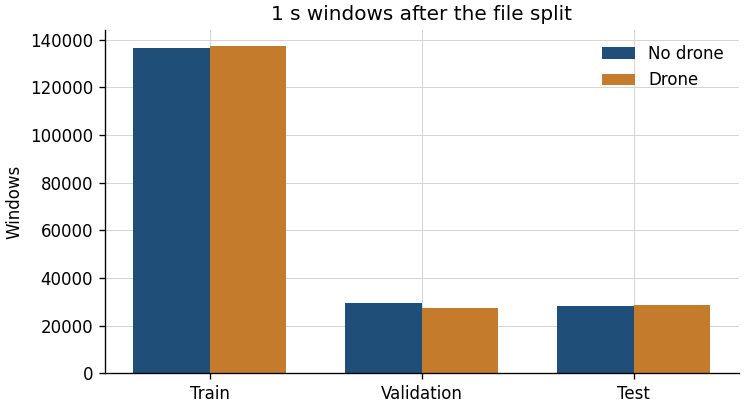

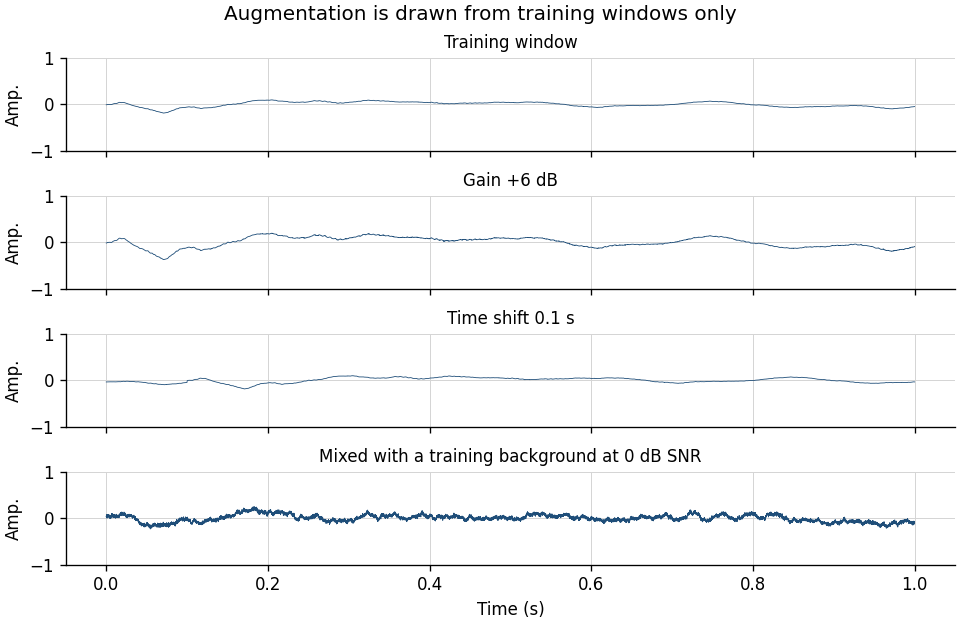

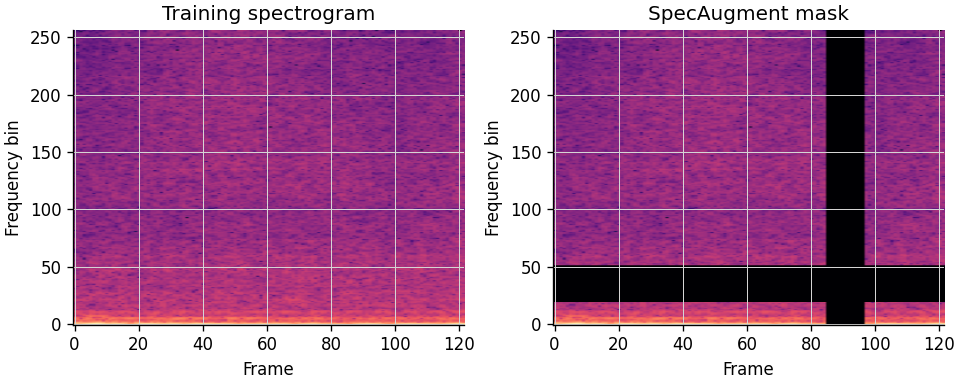

In [5]:
import hashlib
import json
from io import BytesIO
from pathlib import Path
import wave

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Image, display
from datasets import Audio, load_dataset

SR = 16_000
WIN = SR            # 1.0 s
HOP = SR // 2       # 0.5 s
MIN_SAMPLES = SR // 2
SILENCE_DB = -60.0
SEED = 42
LABEL = {0: "No drone", 1: "Drone"}
PROCESSED_DIR = Path.cwd() / "dataset2-processed"


def read_wav(blob):
    with wave.open(BytesIO(blob), "rb") as handle:
        channels = handle.getnchannels()
        width = handle.getsampwidth()
        rate = handle.getframerate()
        frames = handle.getnframes()
        raw = handle.readframes(frames)
    return channels, width, rate, raw


def window_specs(n_samples):
    if n_samples < MIN_SAMPLES:
        return []
    if n_samples < WIN:
        return [(0, int(n_samples), True)]
    return [(start, WIN, False) for start in range(0, n_samples - WIN + 1, HOP)]


def rms_db(samples):
    if samples.size == 0:
        return -120.0
    rms = float(np.sqrt(np.mean(samples.astype(np.float64) ** 2)))
    return 20.0 * np.log10(max(rms / 32768.0, 1e-12))


train = load_dataset("Z121mm/drone-audio-detection-samples")["train"].cast_column("audio", Audio(decode=False))
rows = []
seen = {}
n_format = 0
n_short = 0
n_duplicate = 0
n_silent = 0
n_all_silent = 0
n_padded = 0

for index, row in enumerate(train):
    if index and index % 40000 == 0:
        print(f"read {index:,} files", flush=True)
    blob = row["audio"]["bytes"]
    digest = hashlib.md5(blob).hexdigest()
    label = int(row["label"])
    if digest in seen:
        n_duplicate += 1
        if seen[digest] != label:
            raise RuntimeError(f"Identical audio at row {index} has a different label.")
        continue
    try:
        channels, width, rate, raw = read_wav(blob)
    except (wave.Error, EOFError):
        n_format += 1
        continue
    if channels != 1 or width != 2 or rate != SR or not raw:
        n_format += 1
        continue
    samples = np.frombuffer(raw, dtype="<i2")
    seen[digest] = label
    pieces = window_specs(samples.size)
    if not pieces:
        n_short += 1
        continue
    kept = []
    for start, n_samples, padded in pieces:
        piece = samples[start:start + n_samples]
        if rms_db(piece) < SILENCE_DB:
            n_silent += 1
            continue
        kept.append((start, n_samples, padded))
    if not kept:
        n_all_silent += 1
        continue
    for start, n_samples, padded in kept:
        if padded:
            n_padded += 1
        rows.append({
            "row_index": index,
            "label": label,
            "group_id": digest,
            "start_sample": start,
            "n_samples": n_samples,
            "padded": padded,
        })

windows = pd.DataFrame(rows)
groups = windows.groupby("group_id", sort=False).label.first().rename("label").reset_index()
if windows.groupby("group_id").label.nunique().max() != 1:
    raise RuntimeError("A file group contains both labels.")

rng = np.random.default_rng(SEED)
assignment = {}
for label, part in groups.groupby("label"):
    order = part.group_id.to_numpy().copy()
    rng.shuffle(order)
    n = len(order)
    n_train = int(round(n * 0.70))
    n_val = int(round(n * 0.15))
    if n < 3:
        raise RuntimeError(f"Label {label} has only {n} files.")
    n_train = min(max(n_train, 1), n - 2)
    n_val = min(max(n_val, 1), n - n_train - 1)
    for group_id in order[:n_train]:
        assignment[group_id] = "train"
    for group_id in order[n_train:n_train + n_val]:
        assignment[group_id] = "val"
    for group_id in order[n_train + n_val:]:
        assignment[group_id] = "test"

windows["split"] = windows.group_id.map(assignment)
if windows.split.isna().any():
    raise RuntimeError("A window was left without a split.")
if windows.groupby("group_id").split.nunique().max() != 1:
    raise RuntimeError("A file was assigned to more than one split.")
if windows.groupby("row_index").split.nunique().max() != 1:
    raise RuntimeError("Windows from one file fell into two splits.")
held = {name: set(windows.loc[windows.split == name, "group_id"]) for name in ("train", "val", "test")}
overlap = len(held["train"] & held["val"]) + len(held["train"] & held["test"]) + len(held["val"] & held["test"])
if overlap:
    raise RuntimeError(f"Splits share {overlap} files.")

train_counts = windows.loc[windows.split == "train", "label"].value_counts().sort_index()
class_weight = {int(label): float(train_counts.sum() / (2.0 * count)) for label, count in train_counts.items()}

PROCESSED_DIR.mkdir(parents=True, exist_ok=True)
windows.to_csv(PROCESSED_DIR / "windows.csv", index=False)
(PROCESSED_DIR / "class_weights.json").write_text(json.dumps({
    "computed_from": "train windows",
    "no_drone": class_weight[0],
    "drone": class_weight[1],
}, indent=2))

summary = (
    windows.groupby(["split", "label"])
    .agg(windows=("row_index", "size"), files=("group_id", "nunique"))
    .reset_index()
)
summary["class_name"] = summary.label.map(LABEL)
summary["split"] = pd.Categorical(summary["split"], ["train", "val", "test"], ordered=True)
summary = summary.sort_values(["split", "label"])[["split", "class_name", "windows", "files"]]
display(summary.style.format({"windows": "{:,}", "files": "{:,}"}).hide(axis="index"))
print(f"Files rejected for format: {n_format:,}")
print(f"Clips shorter than 0.5 s dropped: {n_short:,}")
print(f"Duplicate copies skipped: {n_duplicate:,}")
print(f"Windows quieter than {SILENCE_DB:.0f} dBFS dropped: {n_silent:,}")
print(f"Files dropped because every window was that quiet: {n_all_silent:,}")
print(f"Windows padded to 1.0 s: {n_padded:,}")
print(f"Most windows from one file: {int(windows.groupby('group_id').size().max())}")
print(f"File overlap between train, validation, and test: {overlap}")
print(f"Training class weight: no drone {class_weight[0]:.3f}, drone {class_weight[1]:.3f}")
print(f"Window list: {PROCESSED_DIR / 'windows.csv'}")

fig, ax = plt.subplots(figsize=(6.2, 3.4), layout="constrained")
splits = ["train", "val", "test"]
x = np.arange(len(splits))
width = 0.36
for offset, class_id, name, color in ((-width / 2, 0, "No drone", "#1f4e79"), (width / 2, 1, "Drone", "#c47b2b")):
    heights = [
        int(((windows.split == split) & (windows.label == class_id)).sum())
        for split in splits
    ]
    ax.bar(x + offset, heights, width=width, label=name, color=color)
ax.set_xticks(x)
ax.set_xticklabels(["Train", "Validation", "Test"])
ax.set_ylabel("Windows")
ax.set_title("1 s windows after the file split")
ax.legend()
def show(fig):
    buf = BytesIO()
    fig.savefig(buf, format="png", dpi=120)
    display(Image(data=buf.getvalue()))
    plt.close(fig)

show(fig)


def load_window(record):
    blob = train[int(record.row_index)]["audio"]["bytes"]
    _, _, _, raw = read_wav(blob)
    samples = np.frombuffer(raw, dtype="<i2").astype(np.float32) / np.float32(32768.0)
    piece = samples[int(record.start_sample):int(record.start_sample) + int(record.n_samples)]
    if bool(record.padded):
        padded = np.zeros(WIN, dtype=np.float32)
        padded[:piece.size] = piece
        return padded
    return piece


def mix_at_snr(drone, background, snr_db):
    drone_rms = np.sqrt(np.mean(drone ** 2) + 1e-12)
    background_rms = np.sqrt(np.mean(background ** 2) + 1e-12)
    scaled = background * (drone_rms / (background_rms * 10 ** (snr_db / 20.0)))
    mixed = drone + scaled
    peak = np.max(np.abs(mixed))
    if peak > 1:
        mixed = mixed / peak
    return mixed


def spectrogram_db(samples):
    nperseg, hop = 512, 128
    frame = np.lib.stride_tricks.sliding_window_view(samples, nperseg)[::hop]
    power = np.abs(np.fft.rfft(frame * np.hanning(nperseg), axis=1)) ** 2
    db = 10 * np.log10(power.T + 1e-12)
    return db - db.max()


demo = np.random.default_rng(SEED)
train_windows = windows[windows.split == "train"]
drone_pool = train_windows[(train_windows.label == 1) & ~train_windows.padded]
if drone_pool.empty:
    drone_pool = train_windows[train_windows.label == 1]
background_pool = train_windows[(train_windows.label == 0) & ~train_windows.padded]
if background_pool.empty:
    background_pool = train_windows[train_windows.label == 0]
drone_row = drone_pool.sample(1, random_state=SEED).iloc[0]
background_row = background_pool.sample(1, random_state=SEED).iloc[0]
drone = load_window(drone_row)
background = load_window(background_row)
gained = np.clip(drone * 10 ** (6 / 20), -1, 1)
shifted = np.roll(drone, 1_600)
mixed = mix_at_snr(drone, background, snr_db=0.0)

fig, axes = plt.subplots(4, 1, figsize=(8, 5.2), sharex=True, layout="constrained")
time_s = np.arange(WIN) / SR
for ax, signal, title in zip(
    axes,
    (drone, gained, shifted, mixed),
    ("Training window", "Gain +6 dB", "Time shift 0.1 s", "Mixed with a training background at 0 dB SNR"),
):
    ax.plot(time_s, signal, color="#1f4e79", linewidth=0.5)
    ax.set_ylim(-1, 1)
    ax.set_ylabel("Amp.")
    ax.set_title(title, fontsize=10)
axes[-1].set_xlabel("Time (s)")
fig.suptitle("Augmentation is drawn from training windows only", fontsize=12)
show(fig)

original = spectrogram_db(drone)
masked = original.copy()
freq_width = original.shape[0] // 8
time_width = max(original.shape[1] // 10, 1)
f0 = int(demo.integers(0, original.shape[0] - freq_width))
masked[f0:f0 + freq_width, :] = original.min()
t0 = int(demo.integers(0, original.shape[1] - time_width))
masked[:, t0:t0 + time_width] = original.min()
fig, axes = plt.subplots(1, 2, figsize=(8, 3.2), layout="constrained")
for ax, image, title in zip(axes, (original, masked), ("Training spectrogram", "SpecAugment mask")):
    ax.imshow(image, origin="lower", aspect="auto", cmap="magma")
    ax.set_title(title)
    ax.set_xlabel("Frame")
    ax.set_ylabel("Frequency bin")
show(fig)


## 3. Feature extraction

Each 1 s window from the section 2.2 list is used twice. The transformer and the CNN share one feature. The random forest gets a short vector from the same windows. Both are scaled from the training windows only, then saved. Validation and test do not enter either scale. Test files stay closed until an evaluation cell opens them.

**Log-mel, for the transformer and the CNN.** 128 mel bins, a 25 ms window, and a 10 ms hop. A 1 s window is 98 frames. The clips stay at 1 s. The array for each split is `float16`, shape `(windows, 128, 98)`, with a matching label file. The training per-bin mean and standard deviation are saved beside them. A full copy is about 10 GB, under `features-dataset2/`, and it is not committed to git.

**MFCCs, for the random forest.** A forest cannot take the 128 × 98 image: that is 12,544 numbers per window. On each window, compute 13 MFCCs plus the energy, then the first and second differences over time. Save the mean and the standard deviation of each of those series. One window becomes one vector of 84 numbers. The same training-only scale is applied, and train, validation, and test are saved as separate arrays with their labels. This table is small enough to load in one step.

Later sections only load these files. They do not rebuild the spectrograms from the wav files.


Resolving data files:   0%|          | 0/39 [00:00<?, ?it/s]

Resolving data files:   0%|          | 0/39 [00:00<?, ?it/s]

read 20,000 files
read 40,000 files
read 60,000 files
read 80,000 files
read 100,000 files
read 120,000 files
read 140,000 files
read 160,000 files


,split,windows,mel bins,frames
0,train,273820,128,98
1,val,57004,128,98
2,test,57015,128,98


Files read: 179,325
File overlap between train, validation, and test: 0
Feature: log-mel, 128 bins, 25 ms window, 10 ms hop, log(power + 1e-6)
Scale: per-bin mean and standard deviation of the training windows only
Training scale mean across bins: -5.798
Training scale std across bins: 5.420
A float16 cache of every window would be 9.7 GB. It is not written.
Training scale: /content/features-dataset2


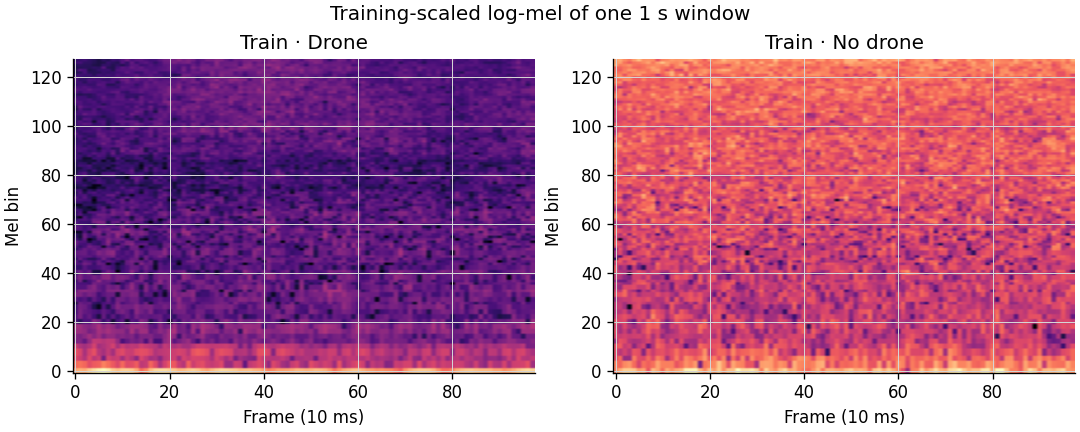

In [6]:
import json
from io import BytesIO
from pathlib import Path
import wave

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Image, display
from datasets import Audio, load_dataset

SR = 16_000
WIN = SR
N_MELS = 128
N_FFT = 400          # 25 ms at 16 kHz
HOP = 160            # 10 ms
FMIN = 20.0
FMAX = 8_000.0
N_FRAMES = 1 + (WIN - N_FFT) // HOP
BATCH = 64
LABEL = {0: "No drone", 1: "Drone"}
PROCESSED_DIR = Path.cwd() / "dataset2-processed"
FEATURES_DIR = Path.cwd() / "features-dataset2"


def read_pcm(blob):
    with wave.open(BytesIO(blob), "rb") as handle:
        if handle.getnchannels() != 1 or handle.getsampwidth() != 2 or handle.getframerate() != SR:
            raise ValueError("A window file is not mono 16-bit 16 kHz.")
        raw = handle.readframes(handle.getnframes())
    return np.frombuffer(raw, dtype="<i2").astype(np.float32) * np.float32(1.0 / 32768.0)


def mel_filterbank(sr, n_fft, n_mels, fmin, fmax):
    def hz_to_mel(hz):
        return 2595.0 * np.log10(1.0 + hz / 700.0)

    def mel_to_hz(mel):
        return 700.0 * (10.0 ** (mel / 2595.0) - 1.0)

    points = np.linspace(hz_to_mel(fmin), hz_to_mel(fmax), n_mels + 2)
    bins = np.floor((n_fft + 1) * mel_to_hz(points) / sr).astype(int)
    bank = np.zeros((n_mels, n_fft // 2 + 1), dtype=np.float32)
    for i in range(n_mels):
        left, center, right = int(bins[i]), int(bins[i + 1]), int(bins[i + 2])
        if center <= left:
            center = left + 1
        if right <= center:
            right = center + 1
        for j in range(left, center):
            if 0 <= j < bank.shape[1]:
                bank[i, j] = (j - left) / (center - left)
        for j in range(center, right):
            if 0 <= j < bank.shape[1]:
                bank[i, j] = (right - j) / (right - center)
    return bank


def log_mel_batch(batch, bank, stft_window):
    frames = np.lib.stride_tricks.sliding_window_view(batch, N_FFT, axis=1)[:, ::HOP, :]
    power = np.abs(np.fft.rfft(frames * stft_window, axis=-1)) ** 2
    mel = np.log(power @ bank.T + 1e-6)
    return mel.astype(np.float32).transpose(0, 2, 1)


def show(fig):
    buf = BytesIO()
    fig.savefig(buf, format="png", dpi=120)
    display(Image(data=buf.getvalue()))
    plt.close(fig)


if N_FRAMES != 98:
    raise RuntimeError(f"A 1 s window produced {N_FRAMES} frames, expected 98.")

windows = pd.read_csv(PROCESSED_DIR / "windows.csv")
if windows.groupby("group_id").split.nunique().max() != 1:
    raise RuntimeError("The window list places one file in two splits.")
if windows.groupby("row_index").split.nunique().max() != 1:
    raise RuntimeError("Windows from one file fall into two splits.")
held = {name: set(windows.loc[windows.split == name, "group_id"]) for name in ("train", "val", "test")}
overlap = len(held["train"] & held["val"]) + len(held["train"] & held["test"]) + len(held["val"] & held["test"])
if overlap:
    raise RuntimeError(f"Splits share {overlap} files.")

bank = mel_filterbank(SR, N_FFT, N_MELS, FMIN, FMAX)
stft_window = np.hanning(N_FFT).astype(np.float32)
probe = log_mel_batch(np.zeros((2, WIN), dtype=np.float32), bank, stft_window)
if probe.shape != (2, N_MELS, N_FRAMES) or not np.isfinite(probe).all():
    raise RuntimeError(f"Log-mel probe shape is {probe.shape}.")

train_rows = windows[windows.split == "train"]
examples = {}
for label_id, name in LABEL.items():
    pool = train_rows[(train_rows.label == label_id) & ~train_rows.padded]
    if pool.empty:
        pool = train_rows[train_rows.label == label_id]
    chosen = pool.sample(1, random_state=42).iloc[0]
    examples[(int(chosen.row_index), int(chosen.start_sample))] = name
example_mel = {}

order = np.argsort(windows.row_index.to_numpy(), kind="mergesort")
row_ids = windows.row_index.to_numpy()[order]
starts = windows.start_sample.to_numpy()[order]
lengths = windows.n_samples.to_numpy()[order]
padded = windows.padded.to_numpy()[order]
splits = windows.split.to_numpy()[order]
groups = {}
for position, row_index in enumerate(row_ids):
    groups.setdefault(int(row_index), []).append(position)

dataset = load_dataset("Z121mm/drone-audio-detection-samples")["train"].cast_column("audio", Audio(decode=False))
sum_bins = np.zeros(N_MELS, dtype=np.float64)
sumsq_bins = np.zeros(N_MELS, dtype=np.float64)
converted = {name: 0 for name in ("train", "val", "test")}
n_train = 0
batch_waves = []
batch_splits = []
batch_keys = []


def flush():
    global n_train
    if not batch_waves:
        return
    specs = log_mel_batch(np.stack(batch_waves), bank, stft_window)
    if specs.shape != (len(batch_waves), N_MELS, N_FRAMES):
        raise RuntimeError(f"Log-mel batch shape is {specs.shape}.")
    train_ix = [i for i, name in enumerate(batch_splits) if name == "train"]
    if train_ix:
        block = specs[train_ix].astype(np.float64)
        sum_bins[:] += block.sum(axis=(0, 2))
        sumsq_bins[:] += np.square(block).sum(axis=(0, 2))
        n_train += len(train_ix)
    for index, key in enumerate(batch_keys):
        if key in examples:
            example_mel[examples[key]] = specs[index].copy()
        converted[batch_splits[index]] += 1
    batch_waves.clear()
    batch_splits.clear()
    batch_keys.clear()


n_files = 0
for row_index, row in enumerate(dataset):
    positions = groups.get(row_index)
    if positions is None:
        continue
    samples = read_pcm(row["audio"]["bytes"])
    for position in positions:
        start = int(starts[position])
        length = int(lengths[position])
        if start < 0 or start + length > samples.size:
            raise RuntimeError(f"Row {row_index} window does not fit the file.")
        piece = samples[start:start + length]
        if bool(padded[position]):
            waveform = np.zeros(WIN, dtype=np.float32)
            waveform[:piece.size] = piece
        elif piece.size != WIN:
            raise RuntimeError(f"Row {row_index} window is {piece.size} samples.")
        else:
            waveform = np.ascontiguousarray(piece)
        batch_waves.append(waveform)
        batch_splits.append(str(splits[position]))
        batch_keys.append((row_index, start))
        if len(batch_waves) == BATCH:
            flush()
    n_files += 1
    if n_files % 20000 == 0:
        print(f"read {n_files:,} files", flush=True)
flush()

for name in ("train", "val", "test"):
    if converted[name] != int((windows.split == name).sum()):
        raise RuntimeError(f"{name}: converted {converted[name]:,}, window list has {int((windows.split == name).sum()):,}.")
if n_train != int((windows.split == "train").sum()):
    raise RuntimeError("Training windows were not all scaled.")
if set(example_mel) != set(LABEL.values()):
    raise RuntimeError("A training example spectrogram was not captured.")

n_positions = n_train * N_FRAMES
mel_mean = (sum_bins / n_positions).astype(np.float32)
variance = sumsq_bins / n_positions - np.square(mel_mean.astype(np.float64))
mel_std = np.sqrt(np.maximum(variance, 0.0)).astype(np.float32)
mel_std = np.maximum(mel_std, np.float32(1e-6))
if not np.isfinite(mel_mean).all() or not np.isfinite(mel_std).all():
    raise RuntimeError("The training scale is not finite.")

FEATURES_DIR.mkdir(parents=True, exist_ok=True)
np.save(FEATURES_DIR / "train_logmel_mean.npy", mel_mean)
np.save(FEATURES_DIR / "train_logmel_std.npy", mel_std)
(FEATURES_DIR / "feature_config.json").write_text(json.dumps({
    "n_mels": N_MELS,
    "n_fft": N_FFT,
    "hop": HOP,
    "fmin": FMIN,
    "fmax": FMAX,
    "n_frames": N_FRAMES,
    "log": "log(mel power + 1e-6)",
    "scale": "per-bin mean and standard deviation of training windows only",
    "window_list": "dataset2-processed/windows.csv",
}, indent=2))
reloaded = np.load(FEATURES_DIR / "train_logmel_mean.npy")
if reloaded.shape != (N_MELS,) or not np.allclose(reloaded, mel_mean):
    raise RuntimeError("The saved training scale does not match the training spectrograms.")

shape_table = pd.DataFrame([
    {"split": name, "windows": int(converted[name]), "mel bins": N_MELS, "frames": N_FRAMES}
    for name in ("train", "val", "test")
])
display(shape_table)
cache_gb = len(windows) * N_MELS * N_FRAMES * 2 / 1e9
print(f"Files read: {n_files:,}")
print(f"File overlap between train, validation, and test: {overlap}")
print("Feature: log-mel, 128 bins, 25 ms window, 10 ms hop, log(power + 1e-6)")
print("Scale: per-bin mean and standard deviation of the training windows only")
print(f"Training scale mean across bins: {float(mel_mean.mean()):.3f}")
print(f"Training scale std across bins: {float(mel_std.mean()):.3f}")
print(f"A float16 cache of every window would be {cache_gb:.1f} GB. It is not written.")
print(f"Training scale: {FEATURES_DIR}")

fig, axes = plt.subplots(1, 2, figsize=(9, 3.6), layout="constrained")
for ax, name in zip(axes, ("Drone", "No drone")):
    scaled = (example_mel[name] - mel_mean[:, None]) / mel_std[:, None]
    ax.imshow(scaled, origin="lower", aspect="auto", cmap="magma")
    ax.set_title(f"Train · {name}")
    ax.set_xlabel("Frame (10 ms)")
    ax.set_ylabel("Mel bin")
fig.suptitle("Training-scaled log-mel of one 1 s window", fontsize=12)
show(fig)


## 4. Transformer model

The AudioSet AST (`MIT/ast-finetuned-audioset-10-10-0.4593`) classifies about 10 s of Kaldi filterbank into 527 classes. These windows are 1 s, and section 3 already fixed the log-mel and the training scale. Changing that checkpoint's length does not resize its position embeddings; a mismatched tensor is reinitialized. The checkpoint is not loaded.

The classifier is a spectrogram transformer on the 128 × 98 training-scaled log-mel. Each window is split into patches, a class token is prepended, and only that token is classified. The output is two logits: no drone, then drone. Training and evaluation of this model are the next two sections. The CNN and the random forest are separate sections after that, and they load the saved features rather than sharing this training run.


In [ ]:
from pathlib import Path
import numpy as np
import pandas as pd
import torch
from torch import nn
from IPython.display import display

N_MELS = 128
N_FRAMES = 98
PATCH_F = 16
PATCH_T = 7
D_MODEL = 128
N_HEADS = 4
N_LAYERS = 4
D_FF = 256
DROPOUT = 0.1
N_CLASSES = 2
SEED = 42
FEATURES_DIR = Path.cwd() / "features-dataset2"


class SpectrogramTransformer(nn.Module):
    """Transformer classifier over patches of one log-mel window."""

    def __init__(
        self,
        n_mels=N_MELS,
        n_frames=N_FRAMES,
        patch_f=PATCH_F,
        patch_t=PATCH_T,
        d_model=D_MODEL,
        n_heads=N_HEADS,
        n_layers=N_LAYERS,
        d_ff=D_FF,
        dropout=DROPOUT,
        n_classes=N_CLASSES,
    ):
        super().__init__()
        if n_mels % patch_f or n_frames % patch_t:
            raise ValueError("Patch size must divide the spectrogram.")
        self.grid_f = n_mels // patch_f
        self.grid_t = n_frames // patch_t
        self.n_patches = self.grid_f * self.grid_t
        self.patch = nn.Conv2d(1, d_model, kernel_size=(patch_f, patch_t), stride=(patch_f, patch_t))
        self.cls = nn.Parameter(torch.zeros(1, 1, d_model))
        self.pos = nn.Parameter(torch.zeros(1, 1 + self.n_patches, d_model))
        layer = nn.TransformerEncoderLayer(
            d_model=d_model,
            nhead=n_heads,
            dim_feedforward=d_ff,
            dropout=dropout,
            activation="gelu",
            batch_first=True,
            norm_first=True,
        )
        self.encoder = nn.TransformerEncoder(layer, num_layers=n_layers, enable_nested_tensor=False)
        self.norm = nn.LayerNorm(d_model)
        self.head = nn.Linear(d_model, n_classes)
        nn.init.trunc_normal_(self.cls, std=0.02)
        nn.init.trunc_normal_(self.pos, std=0.02)

    def forward(self, spectrogram):
        # spectrogram: (batch, mel, time), already scaled by the training mean and standard deviation
        tokens = self.patch(spectrogram.unsqueeze(1))
        tokens = tokens.flatten(2).transpose(1, 2)
        cls = self.cls.expand(spectrogram.size(0), -1, -1)
        tokens = torch.cat([cls, tokens], dim=1) + self.pos
        encoded = self.encoder(tokens)
        return self.head(self.norm(encoded[:, 0]))


class SpectrogramCNN(nn.Module):
    """Small convolutional baseline on the same log-mel window."""

    def __init__(self, n_classes=N_CLASSES):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(1, 32, kernel_size=3, padding=1),
            nn.GELU(),
            nn.MaxPool2d(2),
            nn.Conv2d(32, 64, kernel_size=3, padding=1),
            nn.GELU(),
            nn.MaxPool2d(2),
            nn.Conv2d(64, 128, kernel_size=3, padding=1),
            nn.GELU(),
            nn.AdaptiveAvgPool2d(1),
        )
        self.head = nn.Linear(128, n_classes)

    def forward(self, spectrogram):
        hidden = self.features(spectrogram.unsqueeze(1)).flatten(1)
        return self.head(hidden)


mel_mean = np.load(FEATURES_DIR / "train_logmel_mean.npy")
mel_std = np.load(FEATURES_DIR / "train_logmel_std.npy")
if mel_mean.shape != (N_MELS,) or mel_std.shape != (N_MELS,):
    raise RuntimeError(f"Training scale shape is {mel_mean.shape}, expected ({N_MELS},).")

torch.manual_seed(SEED)
transformer = SpectrogramTransformer()
torch.manual_seed(SEED)
baseline = SpectrogramCNN()
transformer.eval()
baseline.eval()

probe = torch.randn(4, N_MELS, N_FRAMES)
with torch.no_grad():
    transformer_logits = transformer(probe)
    baseline_logits = baseline(probe)
if transformer_logits.shape != (4, 2) or baseline_logits.shape != (4, 2):
    raise RuntimeError(f"Logit shapes are {tuple(transformer_logits.shape)} and {tuple(baseline_logits.shape)}.")


def n_parameters(module):
    return sum(parameter.numel() for parameter in module.parameters())


summary = pd.DataFrame([
    {
        "model": "Spectrogram transformer",
        "role": "classifier",
        "input": f"{N_MELS} × {N_FRAMES} log-mel",
        "tokens": f"{transformer.n_patches} patches + 1 class token",
        "parameters": f"{n_parameters(transformer):,}",
    },
    {
        "model": "Spectrogram CNN",
        "role": "baseline",
        "input": f"{N_MELS} × {N_FRAMES} log-mel",
        "tokens": "three conv layers, then a linear head",
        "parameters": f"{n_parameters(baseline):,}",
    },
])
display(summary)
print(f"Patch: {PATCH_F} × {PATCH_T}. Width {D_MODEL}, {N_HEADS} heads, {N_LAYERS} layers.")
print("The class token is the only transformer vector that reaches the decision layer.")
print("Logits: index 0 is no drone, index 1 is drone.")
print("A probe batch of 4 windows produced logits", tuple(transformer_logits.shape), "and", tuple(baseline_logits.shape))
print("The models do not normalize. Apply the training scale from features-dataset2 before the forward pass.")


,model,role,input,tokens,parameters
0,Spectrogram transformer,classifier,128 × 98 log-mel,112 patches + 1 class token,"559,490"
1,Spectrogram CNN,baseline,128 × 98 log-mel,"three conv layers, then a linear head","92,930"


Patch: 16 × 7. Width 128, 4 heads, 4 layers.
The class token is the only transformer vector that reaches the decision layer.
Logits: index 0 is no drone, index 1 is drone.
A probe batch of 4 windows produced logits (4, 2) and (4, 2)
The models do not normalize. Apply the training scale from features-dataset2 before the forward pass.


## 5. Training

The transformer is trained from scratch. There is no pretrained trunk, so the first epochs are not head-only, and the learning rate is 3e-4 rather than the 1e-5 to 5e-5 range used to fine-tune the AudioSet AST.

Loss is weighted cross-entropy. The weight comes from the training windows only. Those two classes already have almost the same number of windows, so the weight is near one and focal loss is not used.

AdamW uses weight decay 0.01, gradient clipping at 1.0, a one-epoch warmup, and then cosine decay. The batch size is 64. SpecAugment masks time and frequency on training batches only. Full precision is used; this model has about 0.56 million parameters.

The checkpoint is the epoch with the best validation ROC-AUC. Training stops if that score does not improve for 5 epochs, and it runs for at most 20. Test windows are not read. The curves are loss, accuracy, and validation ROC-AUC.

Run this cell on a Colab runtime with an A100. Choose that GPU as the runtime, then run the notebook from the top so the window list and the training scale exist before this cell. The dataset downloads from Hugging Face. CUDA uses bfloat16. The spectrograms stay in memory, and test windows are not read. Download `models/spectrogram_transformer_dataset2.pt` when the cell finishes.


Training spectrograms will stay in memory.


Resolving data files:   0%|          | 0/39 [00:00<?, ?it/s]

Resolving data files:   0%|          | 0/39 [00:00<?, ?it/s]

cached 20,000 train and validation files
cached 40,000 train and validation files
cached 60,000 train and validation files
cached 80,000 train and validation files
cached 100,000 train and validation files
cached 120,000 train and validation files
cached 140,000 train and validation files
Cached 273,820 training spectrograms and held 57,004 validation spectrograms in memory.
Test windows were not read.
epoch  1  train loss 0.132  val loss 0.078  val accuracy 0.970  val ROC-AUC 0.998  val drone F1 0.969  kept  (100s)
epoch  2  train loss 0.068  val loss 0.032  val accuracy 0.989  val ROC-AUC 0.999  val drone F1 0.989  kept  (101s)
epoch  3  train loss 0.054  val loss 0.025  val accuracy 0.991  val ROC-AUC 1.000  val drone F1 0.991  kept  (100s)
epoch  4  train loss 0.044  val loss 0.027  val accuracy 0.991  val ROC-AUC 1.000  val drone F1 0.991  (100s)
epoch  5  train loss 0.037  val loss 0.021  val accuracy 0.992  val ROC-AUC 1.000  val drone F1 0.992  kept  (100s)
epoch  6  train loss

epoch,train_loss,train_accuracy,val_loss,val_accuracy,val_roc_auc,val_drone_f1,kept
1,0.132,0.948,0.078,0.970,0.998,0.969,True
2,0.068,0.975,0.032,0.989,0.999,0.989,True
3,0.054,0.980,0.025,0.991,1.000,0.991,True
4,0.044,0.984,0.027,0.991,1.000,0.991,False
5,0.037,0.987,0.021,0.992,1.000,0.992,True
6,0.032,0.989,0.026,0.991,0.999,0.991,False
7,0.027,0.990,0.011,0.996,1.000,0.996,True
8,0.023,0.992,0.017,0.994,1.000,0.994,False
9,0.021,0.993,0.015,0.995,1.000,0.995,True
10,0.018,0.994,0.012,0.997,1.000,0.997,False


Device: NVIDIA A100-SXM4-40GB
Precision: bfloat16
Training windows: 273,820  (137,181 drone, 136,639 no drone)
Validation windows: 57,004
Class weights from the training counts: no drone 1.002, drone 0.998
File overlap between train, validation, and test: 0
Kept epoch 16 with validation ROC-AUC 1.000
Saved checkpoint: /content/models/spectrogram_transformer_dataset2.pt


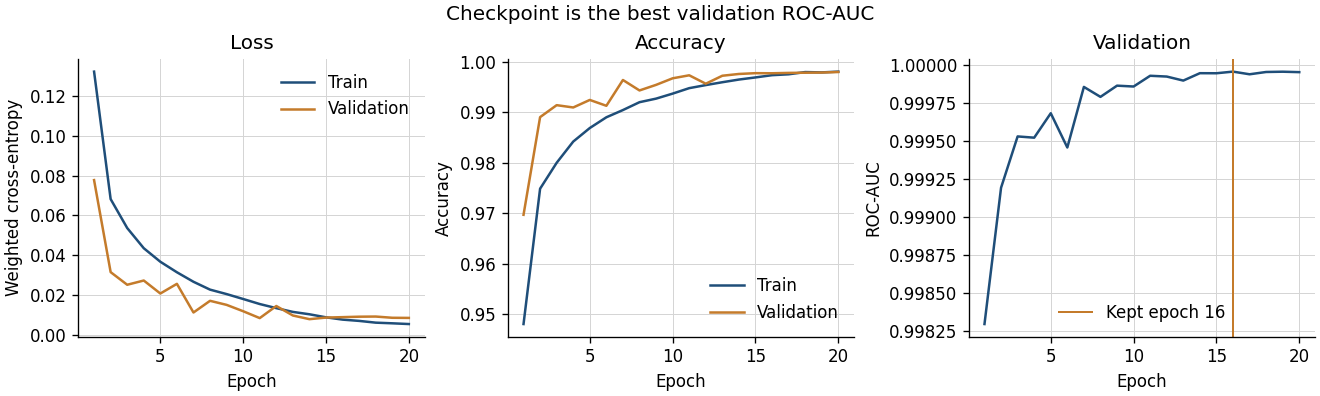

In [ ]:
import math
import os
from pathlib import Path
import shutil
import time
from io import BytesIO
import wave

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from IPython.display import Image, display
try:
    from datasets import Audio, load_dataset
except ImportError:
    import subprocess
    import sys
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "datasets"])
    from datasets import Audio, load_dataset
from torch import nn

SR = 16_000
WIN = SR
N_MELS = 128
N_FRAMES = 98
N_FFT = 400
HOP = 160
FMIN = 20.0
FMAX = 8_000.0
PATCH_F = 16
PATCH_T = 7
D_MODEL = 128
N_HEADS = 4
N_LAYERS = 4
D_FF = 256
DROPOUT = 0.1
N_CLASSES = 2
SEED = 42
MAX_EPOCHS = 20
PATIENCE = 5
BATCH_SIZE = 64
LEARNING_RATE = 3e-4
WEIGHT_DECAY = 0.01
LABEL = {0: "No drone", 1: "Drone"}
PROCESSED_DIR = Path.cwd() / "dataset2-processed"
FEATURES_DIR = Path.cwd() / "features-dataset2"
MODELS_DIR = Path.cwd() / "models"
CACHE_PATH = FEATURES_DIR / "train_logmel_run.npy"


class SpectrogramTransformer(nn.Module):
    """Same classifier as section 4, so this cell can run after a kernel restart."""

    def __init__(self):
        super().__init__()
        if N_MELS % PATCH_F or N_FRAMES % PATCH_T:
            raise ValueError("Patch size must divide the spectrogram.")
        self.grid_f = N_MELS // PATCH_F
        self.grid_t = N_FRAMES // PATCH_T
        self.n_patches = self.grid_f * self.grid_t
        self.patch = nn.Conv2d(1, D_MODEL, kernel_size=(PATCH_F, PATCH_T), stride=(PATCH_F, PATCH_T))
        self.cls = nn.Parameter(torch.zeros(1, 1, D_MODEL))
        self.pos = nn.Parameter(torch.zeros(1, 1 + self.n_patches, D_MODEL))
        layer = nn.TransformerEncoderLayer(
            d_model=D_MODEL,
            nhead=N_HEADS,
            dim_feedforward=D_FF,
            dropout=DROPOUT,
            activation="gelu",
            batch_first=True,
            norm_first=True,
        )
        self.encoder = nn.TransformerEncoder(layer, num_layers=N_LAYERS, enable_nested_tensor=False)
        self.norm = nn.LayerNorm(D_MODEL)
        self.head = nn.Linear(D_MODEL, N_CLASSES)
        nn.init.trunc_normal_(self.cls, std=0.02)
        nn.init.trunc_normal_(self.pos, std=0.02)

    def forward(self, spectrogram):
        tokens = self.patch(spectrogram.unsqueeze(1))
        tokens = tokens.flatten(2).transpose(1, 2)
        cls = self.cls.expand(spectrogram.size(0), -1, -1)
        tokens = torch.cat([cls, tokens], dim=1) + self.pos
        encoded = self.encoder(tokens)
        return self.head(self.norm(encoded[:, 0]))


def read_pcm(blob):
    with wave.open(BytesIO(blob), "rb") as handle:
        if handle.getnchannels() != 1 or handle.getsampwidth() != 2 or handle.getframerate() != SR:
            raise ValueError("A window file is not mono 16-bit 16 kHz.")
        raw = handle.readframes(handle.getnframes())
    return np.frombuffer(raw, dtype="<i2").astype(np.float32) * np.float32(1.0 / 32768.0)


def mel_filterbank(sr, n_fft, n_mels, fmin, fmax):
    def hz_to_mel(hz):
        return 2595.0 * np.log10(1.0 + hz / 700.0)

    def mel_to_hz(mel):
        return 700.0 * (10.0 ** (mel / 2595.0) - 1.0)

    points = np.linspace(hz_to_mel(fmin), hz_to_mel(fmax), n_mels + 2)
    bins = np.floor((n_fft + 1) * mel_to_hz(points) / sr).astype(int)
    bank = np.zeros((n_mels, n_fft // 2 + 1), dtype=np.float32)
    for i in range(n_mels):
        left, center, right = int(bins[i]), int(bins[i + 1]), int(bins[i + 2])
        if center <= left:
            center = left + 1
        if right <= center:
            right = center + 1
        for j in range(left, center):
            if 0 <= j < bank.shape[1]:
                bank[i, j] = (j - left) / (center - left)
        for j in range(center, right):
            if 0 <= j < bank.shape[1]:
                bank[i, j] = (right - j) / (right - center)
    return bank


def log_mel_batch(batch, bank, stft_window):
    frames = np.lib.stride_tricks.sliding_window_view(batch, N_FFT, axis=1)[:, ::HOP, :]
    power = np.abs(np.fft.rfft(frames * stft_window, axis=-1)) ** 2
    mel = np.log(power @ bank.T + 1e-6)
    return mel.astype(np.float32).transpose(0, 2, 1)


def mask_spectrogram(spec):
    """Train-only mask. A masked cell is set to 0, the training mean after scaling."""
    spec = spec.clone()
    n_mels, n_frames = spec.shape
    for _ in range(2):
        width = int(torch.randint(0, 12, (1,)))
        start = int(torch.randint(0, n_mels - width + 1, (1,)))
        spec[start:start + width, :] = 0
    for _ in range(2):
        width = int(torch.randint(0, 8, (1,)))
        start = int(torch.randint(0, n_frames - width + 1, (1,)))
        spec[:, start:start + width] = 0
    return spec


def scores_from(labels, predicted, drone_probability):
    labels = np.asarray(labels)
    predicted = np.asarray(predicted)
    confusion = np.zeros((2, 2), dtype=int)
    for truth, guess in zip(labels, predicted):
        confusion[int(truth), int(guess)] += 1
    true_positive = confusion[1, 1]
    false_positive = confusion[0, 1]
    false_negative = confusion[1, 0]
    precision = true_positive / (true_positive + false_positive) if true_positive + false_positive else 0.0
    recall = true_positive / (true_positive + false_negative) if true_positive + false_negative else 0.0
    f1 = 2 * precision * recall / (precision + recall) if precision + recall else 0.0
    accuracy = (confusion[0, 0] + confusion[1, 1]) / confusion.sum()
    order = np.argsort(-np.asarray(drone_probability))
    ranked = labels[order]
    n_pos = max(int((labels == 1).sum()), 1)
    n_neg = max(int((labels == 0).sum()), 1)
    tpr = np.cumsum(ranked == 1) / n_pos
    fpr = np.cumsum(ranked == 0) / n_neg
    auc = float(np.trapezoid(np.r_[0.0, tpr], np.r_[0.0, fpr]))
    return {
        "accuracy": float(accuracy),
        "drone_precision": float(precision),
        "drone_recall": float(recall),
        "drone_f1": float(f1),
        "roc_auc": auc,
    }


def learning_rate(step, steps_per_epoch):
    warmup = steps_per_epoch
    total = MAX_EPOCHS * steps_per_epoch
    if step < warmup:
        return LEARNING_RATE * (step + 1) / warmup
    progress = min((step - warmup) / max(1, total - warmup), 1.0)
    return LEARNING_RATE * 0.5 * (1.0 + math.cos(math.pi * progress))


def show(fig):
    buf = BytesIO()
    fig.savefig(buf, format="png", dpi=120)
    display(Image(data=buf.getvalue()))
    plt.close(fig)


def set_seed(seed):
    np.random.seed(seed)
    torch.manual_seed(seed)


windows = pd.read_csv(PROCESSED_DIR / "windows.csv")
if windows.groupby("group_id").split.nunique().max() != 1:
    raise RuntimeError("The window list places one file in two splits.")
held = {name: set(windows.loc[windows.split == name, "group_id"]) for name in ("train", "val", "test")}
overlap = len(held["train"] & held["val"]) + len(held["train"] & held["test"]) + len(held["val"] & held["test"])
if overlap:
    raise RuntimeError(f"Splits share {overlap} files.")
use = windows[windows.split.isin(["train", "val"])].reset_index(drop=True)
if (use.split == "test").any():
    raise RuntimeError("Test windows entered the training table.")

order = np.argsort(use.row_index.to_numpy(), kind="mergesort")
row_ids = use.row_index.to_numpy()[order]
starts = use.start_sample.to_numpy()[order]
lengths = use.n_samples.to_numpy()[order]
padded = use.padded.to_numpy()[order]
splits = use.split.to_numpy()[order]
labels = use.label.to_numpy()[order]
slot_of = np.empty(len(order), dtype=np.int64)
counts = {"train": 0, "val": 0}
for index, split_name in enumerate(splits):
    slot_of[index] = counts[split_name]
    counts[split_name] += 1
groups = {}
for position, row_index in enumerate(row_ids):
    groups.setdefault(int(row_index), []).append(position)

mel_mean = np.load(FEATURES_DIR / "train_logmel_mean.npy")
mel_std = np.load(FEATURES_DIR / "train_logmel_std.npy")
if mel_mean.shape != (N_MELS,) or mel_std.shape != (N_MELS,):
    raise RuntimeError("The training scale does not match 128 mel bins.")
bank = mel_filterbank(SR, N_FFT, N_MELS, FMIN, FMAX)
stft_window = np.hanning(N_FFT).astype(np.float32)

def physical_ram():
    try:
        return os.sysconf("SC_PAGE_SIZE") * os.sysconf("SC_PHYS_PAGES")
    except (ValueError, OSError):
        return 0

train_bytes = counts["train"] * N_MELS * N_FRAMES * np.dtype(np.float16).itemsize
val_bytes = counts["val"] * N_MELS * N_FRAMES * np.dtype(np.float16).itemsize
use_memory = torch.cuda.is_available() or physical_ram() > (train_bytes + val_bytes) * 2
used_disk_cache = False
if use_memory:
    train_mel = np.empty((counts["train"], N_MELS, N_FRAMES), dtype=np.float16)
    print("Training spectrograms will stay in memory.", flush=True)
else:
    need_bytes = train_bytes + 2 * 1024**3
    free_bytes = shutil.disk_usage(FEATURES_DIR).free
    if free_bytes < need_bytes:
        raise RuntimeError(
            f"Need {need_bytes / 1e9:.1f} GB free for the temporary training cache, found {free_bytes / 1e9:.1f} GB."
        )
    if CACHE_PATH.exists():
        CACHE_PATH.unlink()
    train_mel = np.lib.format.open_memmap(
        CACHE_PATH, mode="w+", dtype=np.float16, shape=(counts["train"], N_MELS, N_FRAMES)
    )
    used_disk_cache = True
    print("Training spectrograms will use a temporary disk cache.", flush=True)
val_mel = np.empty((counts["val"], N_MELS, N_FRAMES), dtype=np.float16)
train_y = np.full(counts["train"], -1, dtype=np.int8)
val_y = np.full(counts["val"], -1, dtype=np.int8)
history = []
try:
    dataset = load_dataset("Z121mm/drone-audio-detection-samples")["train"].cast_column("audio", Audio(decode=False))
    filled = {"train": 0, "val": 0}
    n_files = 0
    for row_index, row in enumerate(dataset):
        positions = groups.get(row_index)
        if positions is None:
            continue
        samples = read_pcm(row["audio"]["bytes"])
        waves = []
        for position in positions:
            start = int(starts[position])
            length = int(lengths[position])
            piece = samples[start:start + length]
            if bool(padded[position]):
                waveform = np.zeros(WIN, dtype=np.float32)
                waveform[:piece.size] = piece
            else:
                waveform = np.ascontiguousarray(piece)
            waves.append(waveform)
        specs = log_mel_batch(np.stack(waves), bank, stft_window)
        scaled = (specs - mel_mean[None, :, None]) / mel_std[None, :, None]
        split_name = str(splits[positions[0]])
        start_slot = int(slot_of[positions[0]])
        if int(slot_of[positions[-1]]) != start_slot + len(positions) - 1:
            raise RuntimeError(f"Windows of row {row_index} are not contiguous in the cache.")
        target = train_mel if split_name == "train" else val_mel
        target_y = train_y if split_name == "train" else val_y
        target[start_slot:start_slot + len(positions)] = scaled.astype(np.float16)
        target_y[start_slot:start_slot + len(positions)] = labels[positions]
        filled[split_name] += len(positions)
        n_files += 1
        if n_files % 20000 == 0:
            print(f"cached {n_files:,} train and validation files", flush=True)
    del dataset
    if hasattr(train_mel, "flush"):
        train_mel.flush()
    if filled["train"] != counts["train"] or filled["val"] != counts["val"]:
        raise RuntimeError(f"Cached {filled}, expected {counts}.")
    if (train_y < 0).any() or (val_y < 0).any():
        raise RuntimeError("A training or validation window was not given a label.")
    print(
        f"Cached {counts['train']:,} training spectrograms and held {counts['val']:,} validation spectrograms in memory.",
        flush=True,
    )
    print("Test windows were not read.", flush=True)

    if torch.cuda.is_available():
        device = torch.device("cuda")
    elif torch.backends.mps.is_available():
        device = torch.device("mps")
    else:
        device = torch.device("cpu")
    use_bf16 = device.type == "cuda" and torch.cuda.is_bf16_supported()
    set_seed(SEED)
    model = SpectrogramTransformer().to(device)
    train_counts = np.bincount(train_y, minlength=2).astype(np.float32)
    class_weight = torch.tensor(train_counts.sum() / (2.0 * train_counts), dtype=torch.float32, device=device)
    criterion = nn.CrossEntropyLoss(weight=class_weight)
    optimizer = torch.optim.AdamW(model.parameters(), lr=LEARNING_RATE, weight_decay=WEIGHT_DECAY)
    steps_per_epoch = math.ceil(len(train_y) / BATCH_SIZE)
    global_step = 0
    best_auc = -1.0
    best_epoch = 0
    best_state = None
    wait = 0

    val_labels_fixed = val_y.astype(np.int64)
    for epoch in range(1, MAX_EPOCHS + 1):
        started = time.perf_counter()
        model.train()
        total_loss = 0.0
        correct = 0
        seen = 0
        permutation = np.random.default_rng(SEED + epoch).permutation(len(train_y))
        for start in range(0, len(train_y), BATCH_SIZE):
            choice = permutation[start:start + BATCH_SIZE]
            for group in optimizer.param_groups:
                group["lr"] = learning_rate(global_step, steps_per_epoch)
            spectrogram = torch.from_numpy(np.asarray(train_mel[choice], dtype=np.float32))
            spectrogram = torch.stack([mask_spectrogram(item) for item in spectrogram]).to(device)
            label = torch.from_numpy(train_y[choice].astype(np.int64)).to(device)
            optimizer.zero_grad(set_to_none=True)
            with torch.autocast(device_type=device.type, dtype=torch.bfloat16, enabled=use_bf16):
                logits = model(spectrogram)
                loss = criterion(logits, label)
            loss.backward()
            nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            optimizer.step()
            global_step += 1
            total_loss += loss.item() * len(label)
            correct += int((logits.argmax(dim=1) == label).sum().item())
            seen += len(label)
        train_loss = total_loss / seen
        train_accuracy = correct / seen

        model.eval()
        val_loss_total = 0.0
        val_seen = 0
        val_predicted = []
        val_probability = []
        with torch.no_grad():
            for start in range(0, len(val_y), BATCH_SIZE):
                spectrogram = torch.from_numpy(np.asarray(val_mel[start:start + BATCH_SIZE], dtype=np.float32)).to(device)
                label = torch.from_numpy(val_labels_fixed[start:start + BATCH_SIZE]).to(device)
                with torch.autocast(device_type=device.type, dtype=torch.bfloat16, enabled=use_bf16):
                    logits = model(spectrogram)
                    loss = criterion(logits, label)
                val_loss_total += loss.item() * len(label)
                val_seen += len(label)
                val_predicted.append(logits.argmax(dim=1).cpu().numpy())
                val_probability.append(torch.softmax(logits.float(), dim=1)[:, 1].cpu().numpy())
        val_scores = scores_from(val_labels_fixed, np.concatenate(val_predicted), np.concatenate(val_probability))
        val_loss = val_loss_total / val_seen
        improved = val_scores["roc_auc"] > best_auc
        if improved:
            best_auc = val_scores["roc_auc"]
            best_epoch = epoch
            best_state = {name: value.detach().cpu().clone() for name, value in model.state_dict().items()}
            wait = 0
        else:
            wait += 1
        history.append({
            "epoch": epoch,
            "train_loss": train_loss,
            "train_accuracy": train_accuracy,
            "val_loss": val_loss,
            "val_accuracy": val_scores["accuracy"],
            "val_roc_auc": val_scores["roc_auc"],
            "val_drone_f1": val_scores["drone_f1"],
            "kept": improved,
        })
        mark = "  kept" if improved else ""
        print(
            f"epoch {epoch:2d}  train loss {train_loss:.3f}  val loss {val_loss:.3f}  "
            f"val accuracy {val_scores['accuracy']:.3f}  val ROC-AUC {val_scores['roc_auc']:.3f}  "
            f"val drone F1 {val_scores['drone_f1']:.3f}{mark}  ({time.perf_counter() - started:.0f}s)",
            flush=True,
        )
        if wait >= PATIENCE:
            print(f"Stopped after epoch {epoch}. Validation ROC-AUC did not improve for {PATIENCE} epochs.")
            break

    model.load_state_dict(best_state)
    MODELS_DIR.mkdir(parents=True, exist_ok=True)
    checkpoint_path = MODELS_DIR / "spectrogram_transformer_dataset2.pt"
    torch.save({
        "state_dict": best_state,
        "epoch": best_epoch,
        "val_roc_auc": best_auc,
        "class_weight": class_weight.detach().cpu(),
        "config": {
            "n_mels": N_MELS,
            "n_frames": N_FRAMES,
            "patch_f": PATCH_F,
            "patch_t": PATCH_T,
            "d_model": D_MODEL,
            "n_heads": N_HEADS,
            "n_layers": N_LAYERS,
            "d_ff": D_FF,
            "dropout": DROPOUT,
            "n_classes": N_CLASSES,
            "learning_rate": LEARNING_RATE,
            "weight_decay": WEIGHT_DECAY,
            "batch_size": BATCH_SIZE,
        },
    }, checkpoint_path)
finally:
    cache = globals().get("train_mel")
    if cache is not None:
        mapping = getattr(cache, "_mmap", None)
        if mapping is not None:
            mapping.close()
        del cache
        globals().pop("train_mel", None)
    if CACHE_PATH.exists():
        CACHE_PATH.unlink()

if not history:
    raise RuntimeError("Training produced no epochs.")
history_frame = pd.DataFrame(history)
display(history_frame.style.format({
    "train_loss": "{:.3f}",
    "train_accuracy": "{:.3f}",
    "val_loss": "{:.3f}",
    "val_accuracy": "{:.3f}",
    "val_roc_auc": "{:.3f}",
    "val_drone_f1": "{:.3f}",
}).hide(axis="index"))
if device.type == "cuda":
    print(f"Device: {torch.cuda.get_device_name(0)}")
else:
    print(f"Device: {device.type}")
print(f"Precision: {'bfloat16' if use_bf16 else 'float32'}")
print(f"Training windows: {len(train_y):,}  ({int(train_counts[1]):,} drone, {int(train_counts[0]):,} no drone)")
print(f"Validation windows: {len(val_y):,}")
print(f"Class weights from the training counts: no drone {class_weight[0].item():.3f}, drone {class_weight[1].item():.3f}")
print(f"File overlap between train, validation, and test: {overlap}")
print(f"Kept epoch {best_epoch} with validation ROC-AUC {best_auc:.3f}")
print(f"Saved checkpoint: {checkpoint_path}")
if used_disk_cache:
    print("Temporary training spectrograms deleted.")

fig, axes = plt.subplots(1, 3, figsize=(11, 3.3), layout="constrained")
axes[0].plot(history_frame.epoch, history_frame.train_loss, label="Train", color="#1f4e79")
axes[0].plot(history_frame.epoch, history_frame.val_loss, label="Validation", color="#c47b2b")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Weighted cross-entropy")
axes[0].set_title("Loss")
axes[0].legend()
axes[1].plot(history_frame.epoch, history_frame.train_accuracy, label="Train", color="#1f4e79")
axes[1].plot(history_frame.epoch, history_frame.val_accuracy, label="Validation", color="#c47b2b")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Accuracy")
axes[1].set_title("Accuracy")
axes[1].legend()
axes[2].plot(history_frame.epoch, history_frame.val_roc_auc, color="#1f4e79")
axes[2].axvline(best_epoch, color="#c47b2b", linewidth=1.2, label=f"Kept epoch {best_epoch}")
axes[2].set_xlabel("Epoch")
axes[2].set_ylabel("ROC-AUC")
axes[2].set_title("Validation")
axes[2].legend()
fig.suptitle("Checkpoint is the best validation ROC-AUC", fontsize=12)
show(fig)


## 6. Evaluation (baseline transformer)

The held-out test set is scored once, after section 5 has saved the checkpoint. The report is accuracy, drone precision, recall, F1, ROC-AUC, and average precision, next to a majority-class baseline taken from the training windows.

The plots are the test ROC curve, the precision-recall curve, the confusion matrix, and the counts of true positives, true negatives, false positives, and false negatives. A few test windows the model got wrong are shown.

False alarms are the costly mistake, so the operating threshold is chosen on validation, not on the test set. One threshold keeps the validation false-alarm rate at 1 percent, and another keeps it at 5 percent. Those two thresholds are applied to the test set, and the drone detection rate at each one is reported.

This copy of the data has no source label and no signal-to-noise label, so the results are not split by source or by SNR. There is no separate held-out corpus and no private recording set in this run.


Resolving data files:   0%|          | 0/39 [00:00<?, ?it/s]

Resolving data files:   0%|          | 0/39 [00:00<?, ?it/s]

read 20,000 validation and test files
read 40,000 validation and test files


model,accuracy,drone_precision,drone_recall,drone_f1,roc_auc,average_precision
Always drone,0.503,0.503,1.000,0.669,0.500,0.503
Spectrogram transformer,0.999,0.998,0.999,0.999,1.000,1.000


validation_false_alarm,threshold,test_detection_rate,test_false_alarm_rate
1%,0.046,1.000,0.008
5%,0.001,1.000,0.049


Device: NVIDIA A100-SXM4-40GB
Checkpoint epoch 16, validation ROC-AUC 1.000
Test windows: 57,015  (28,681 drone, 28,334 no drone)
Test weighted loss: 0.005
File overlap between train, validation, and test: 0
Thresholds were chosen on validation and applied once to the test set.
This is the only score of the test split.


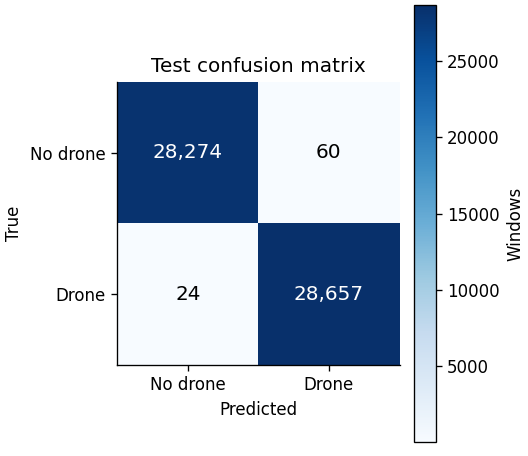

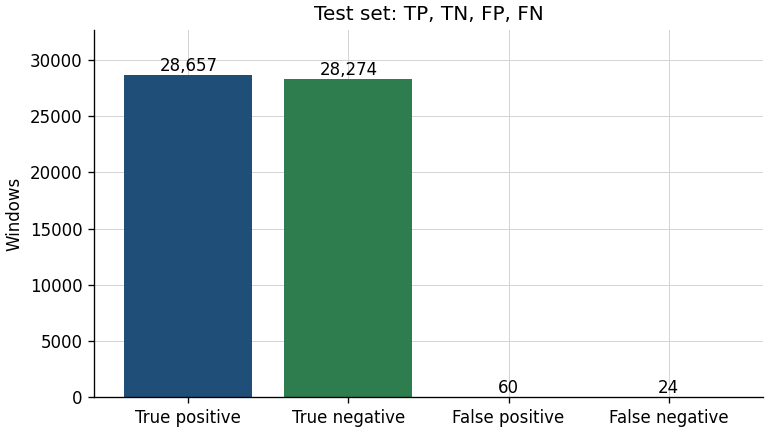

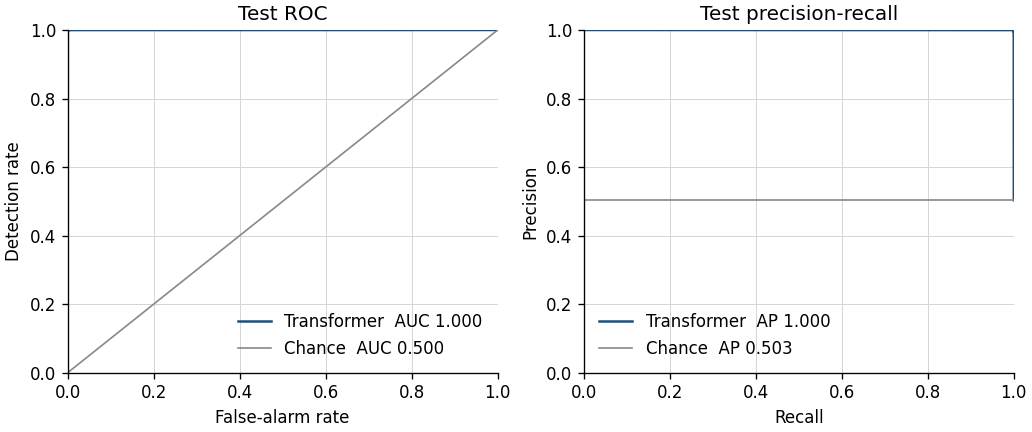

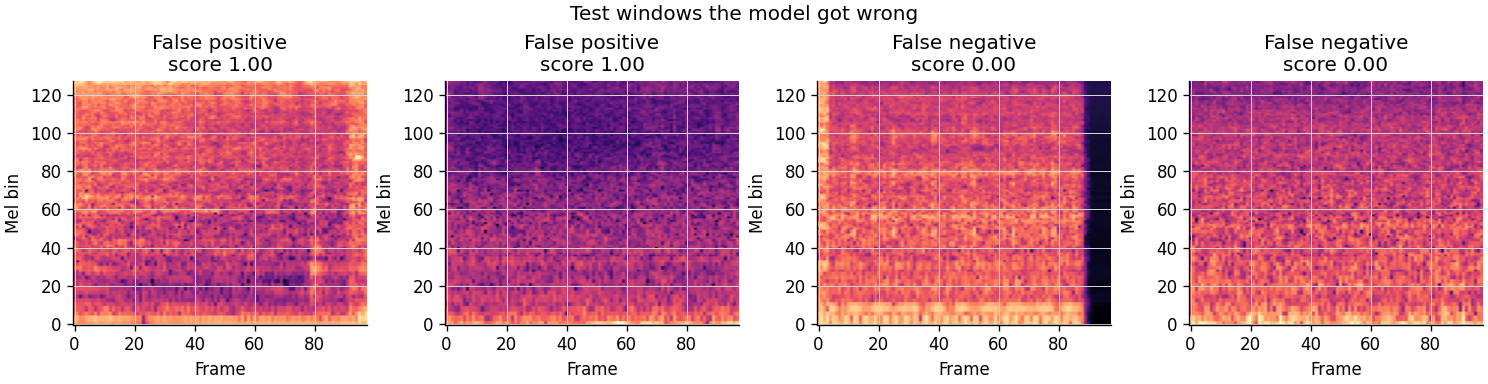

In [ ]:
from pathlib import Path
from io import BytesIO
import wave

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from IPython.display import Image, display
from torch import nn

try:
    from datasets import Audio, load_dataset
except ImportError:
    import subprocess
    import sys
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "datasets"])
    from datasets import Audio, load_dataset

SR = 16_000
WIN = SR
N_MELS = 128
N_FRAMES = 98
N_FFT = 400
HOP = 160
FMIN = 20.0
FMAX = 8_000.0
PATCH_F = 16
PATCH_T = 7
D_MODEL = 128
N_HEADS = 4
N_LAYERS = 4
D_FF = 256
DROPOUT = 0.1
N_CLASSES = 2
BATCH_SIZE = 64
LABEL = {0: "No drone", 1: "Drone"}
PROCESSED_DIR = Path.cwd() / "dataset2-processed"
FEATURES_DIR = Path.cwd() / "features-dataset2"
CHECKPOINT_PATH = Path.cwd() / "models" / "spectrogram_transformer_dataset2.pt"


class SpectrogramTransformer(nn.Module):
    """Same classifier as section 5, loaded from the saved checkpoint."""

    def __init__(self):
        super().__init__()
        if N_MELS % PATCH_F or N_FRAMES % PATCH_T:
            raise ValueError("Patch size must divide the spectrogram.")
        self.grid_f = N_MELS // PATCH_F
        self.grid_t = N_FRAMES // PATCH_T
        self.n_patches = self.grid_f * self.grid_t
        self.patch = nn.Conv2d(1, D_MODEL, kernel_size=(PATCH_F, PATCH_T), stride=(PATCH_F, PATCH_T))
        self.cls = nn.Parameter(torch.zeros(1, 1, D_MODEL))
        self.pos = nn.Parameter(torch.zeros(1, 1 + self.n_patches, D_MODEL))
        layer = nn.TransformerEncoderLayer(
            d_model=D_MODEL,
            nhead=N_HEADS,
            dim_feedforward=D_FF,
            dropout=DROPOUT,
            activation="gelu",
            batch_first=True,
            norm_first=True,
        )
        self.encoder = nn.TransformerEncoder(layer, num_layers=N_LAYERS, enable_nested_tensor=False)
        self.norm = nn.LayerNorm(D_MODEL)
        self.head = nn.Linear(D_MODEL, N_CLASSES)
        nn.init.trunc_normal_(self.cls, std=0.02)
        nn.init.trunc_normal_(self.pos, std=0.02)

    def forward(self, spectrogram):
        tokens = self.patch(spectrogram.unsqueeze(1))
        tokens = tokens.flatten(2).transpose(1, 2)
        cls = self.cls.expand(spectrogram.size(0), -1, -1)
        tokens = torch.cat([cls, tokens], dim=1) + self.pos
        encoded = self.encoder(tokens)
        return self.head(self.norm(encoded[:, 0]))


def read_pcm(blob):
    with wave.open(BytesIO(blob), "rb") as handle:
        if handle.getnchannels() != 1 or handle.getsampwidth() != 2 or handle.getframerate() != SR:
            raise ValueError("A window file is not mono 16-bit 16 kHz.")
        raw = handle.readframes(handle.getnframes())
    return np.frombuffer(raw, dtype="<i2").astype(np.float32) * np.float32(1.0 / 32768.0)


def mel_filterbank(sr, n_fft, n_mels, fmin, fmax):
    def hz_to_mel(hz):
        return 2595.0 * np.log10(1.0 + hz / 700.0)

    def mel_to_hz(mel):
        return 700.0 * (10.0 ** (mel / 2595.0) - 1.0)

    points = np.linspace(hz_to_mel(fmin), hz_to_mel(fmax), n_mels + 2)
    bins = np.floor((n_fft + 1) * mel_to_hz(points) / sr).astype(int)
    bank = np.zeros((n_mels, n_fft // 2 + 1), dtype=np.float32)
    for i in range(n_mels):
        left, center, right = int(bins[i]), int(bins[i + 1]), int(bins[i + 2])
        if center <= left:
            center = left + 1
        if right <= center:
            right = center + 1
        for j in range(left, center):
            if 0 <= j < bank.shape[1]:
                bank[i, j] = (j - left) / (center - left)
        for j in range(center, right):
            if 0 <= j < bank.shape[1]:
                bank[i, j] = (right - j) / (right - center)
    return bank


def log_mel_batch(batch, bank, stft_window):
    frames = np.lib.stride_tricks.sliding_window_view(batch, N_FFT, axis=1)[:, ::HOP, :]
    power = np.abs(np.fft.rfft(frames * stft_window, axis=-1)) ** 2
    mel = np.log(power @ bank.T + 1e-6)
    return mel.astype(np.float32).transpose(0, 2, 1)


def average_precision(labels, probability):
    labels = np.asarray(labels)
    order = np.argsort(-np.asarray(probability))
    ranked = labels[order]
    hits = ranked == 1
    n_pos = max(int(hits.sum()), 1)
    precision = np.cumsum(hits) / np.arange(1, len(ranked) + 1)
    return float(precision[hits].sum() / n_pos)


def rates_at_threshold(labels, probability, threshold):
    labels = np.asarray(labels)
    predicted = (np.asarray(probability) >= threshold).astype(np.int64)
    positives = predicted == 1
    negatives = ~positives
    true_pos = int(((labels == 1) & positives).sum())
    false_pos = int(((labels == 0) & positives).sum())
    false_neg = int(((labels == 1) & negatives).sum())
    true_neg = int(((labels == 0) & negatives).sum())
    n_pos = max(true_pos + false_neg, 1)
    n_neg = max(true_neg + false_pos, 1)
    return {
        "detection_rate": true_pos / n_pos,
        "false_alarm_rate": false_pos / n_neg,
        "threshold": float(threshold),
    }


def threshold_at_false_alarm(labels, probability, target):
    labels = np.asarray(labels)
    probability = np.asarray(probability)
    order = np.argsort(-probability)
    ranked = labels[order]
    scores = probability[order]
    n_neg = max(int((labels == 0).sum()), 1)
    false_alarm = np.cumsum(ranked == 0) / n_neg
    allowed = np.flatnonzero(false_alarm <= target)
    if allowed.size == 0:
        return float(scores[0] + 1.0)
    return float(scores[allowed[-1]])


def show(fig):
    buf = BytesIO()
    fig.savefig(buf, format="png", dpi=120)
    display(Image(data=buf.getvalue()))
    plt.close(fig)


if not CHECKPOINT_PATH.exists():
    raise RuntimeError(
        "No checkpoint yet. Run section 5 first. This cell scores the saved model and does not train."
    )

windows = pd.read_csv(PROCESSED_DIR / "windows.csv")
if windows.groupby("group_id").split.nunique().max() != 1:
    raise RuntimeError("The window list places one file in two splits.")
held = {name: set(windows.loc[windows.split == name, "group_id"]) for name in ("train", "val", "test")}
overlap = len(held["train"] & held["val"]) + len(held["train"] & held["test"]) + len(held["val"] & held["test"])
if overlap:
    raise RuntimeError(f"Splits share {overlap} files.")
train_counts = np.bincount(windows.loc[windows.split == "train", "label"], minlength=2)
majority = int(np.argmax(train_counts))

use = windows[windows.split.isin(["val", "test"])].reset_index(drop=True)
if (use.split == "train").any():
    raise RuntimeError("A training window entered the evaluation table.")
order = np.argsort(use.row_index.to_numpy(), kind="mergesort")
row_ids = use.row_index.to_numpy()[order]
starts = use.start_sample.to_numpy()[order]
lengths = use.n_samples.to_numpy()[order]
padded = use.padded.to_numpy()[order]
splits = use.split.to_numpy()[order]
labels_all = use.label.to_numpy()[order]
slot_of = np.empty(len(order), dtype=np.int64)
counts = {"val": 0, "test": 0}
for index, split_name in enumerate(splits):
    slot_of[index] = counts[split_name]
    counts[split_name] += 1
groups = {}
for position, row_index in enumerate(row_ids):
    groups.setdefault(int(row_index), []).append(position)

mel_mean = np.load(FEATURES_DIR / "train_logmel_mean.npy")
mel_std = np.load(FEATURES_DIR / "train_logmel_std.npy")
bank = mel_filterbank(SR, N_FFT, N_MELS, FMIN, FMAX)
stft_window = np.hanning(N_FFT).astype(np.float32)
store = {
    "val": np.empty((counts["val"], N_MELS, N_FRAMES), dtype=np.float16),
    "test": np.empty((counts["test"], N_MELS, N_FRAMES), dtype=np.float16),
}
store_y = {
    "val": np.full(counts["val"], -1, dtype=np.int8),
    "test": np.full(counts["test"], -1, dtype=np.int8),
}

dataset = load_dataset("Z121mm/drone-audio-detection-samples")["train"].cast_column("audio", Audio(decode=False))
filled = {"val": 0, "test": 0}
n_files = 0
for row_index, row in enumerate(dataset):
    positions = groups.get(row_index)
    if positions is None:
        continue
    samples = read_pcm(row["audio"]["bytes"])
    waves = []
    for position in positions:
        start = int(starts[position])
        length = int(lengths[position])
        piece = samples[start:start + length]
        if bool(padded[position]):
            waveform = np.zeros(WIN, dtype=np.float32)
            waveform[:piece.size] = piece
        else:
            waveform = np.ascontiguousarray(piece)
        waves.append(waveform)
    specs = log_mel_batch(np.stack(waves), bank, stft_window)
    scaled = (specs - mel_mean[None, :, None]) / mel_std[None, :, None]
    split_name = str(splits[positions[0]])
    start_slot = int(slot_of[positions[0]])
    store[split_name][start_slot:start_slot + len(positions)] = scaled.astype(np.float16)
    store_y[split_name][start_slot:start_slot + len(positions)] = labels_all[positions]
    filled[split_name] += len(positions)
    n_files += 1
    if n_files % 20000 == 0:
        print(f"read {n_files:,} validation and test files", flush=True)
del dataset
if filled != counts or (store_y["test"] < 0).any() or (store_y["val"] < 0).any():
    raise RuntimeError(f"Built {filled}, expected {counts}.")

if torch.cuda.is_available():
    device = torch.device("cuda")
elif torch.backends.mps.is_available():
    device = torch.device("mps")
else:
    device = torch.device("cpu")
checkpoint = torch.load(CHECKPOINT_PATH, map_location="cpu", weights_only=False)
model = SpectrogramTransformer().to(device)
model.load_state_dict(checkpoint["state_dict"])
model.eval()
class_weight = checkpoint["class_weight"].to(device)
criterion = nn.CrossEntropyLoss(weight=class_weight)


@torch.no_grad()
def predict(mel, labels):
    labels = np.asarray(labels)
    loss_total = 0.0
    seen = 0
    predicted = []
    probability = []
    for start in range(0, len(labels), BATCH_SIZE):
        spectrogram = torch.from_numpy(np.asarray(mel[start:start + BATCH_SIZE], dtype=np.float32)).to(device)
        label = torch.from_numpy(labels[start:start + BATCH_SIZE].astype(np.int64)).to(device)
        logits = model(spectrogram)
        loss = criterion(logits, label)
        loss_total += loss.item() * len(label)
        seen += len(label)
        predicted.append(logits.argmax(dim=1).cpu().numpy())
        probability.append(torch.softmax(logits, dim=1)[:, 1].cpu().numpy())
    return loss_total / seen, labels.astype(np.int64), np.concatenate(predicted), np.concatenate(probability)


val_loss, val_labels, val_predicted, val_probability = predict(store["val"], store_y["val"])
thresholds = {
    0.01: threshold_at_false_alarm(val_labels, val_probability, 0.01),
    0.05: threshold_at_false_alarm(val_labels, val_probability, 0.05),
}
test_loss, test_labels, test_predicted, test_probability = predict(store["test"], store_y["test"])
del store["val"], store_y["val"]

true_pos = int(((test_labels == 1) & (test_predicted == 1)).sum())
false_pos = int(((test_labels == 0) & (test_predicted == 1)).sum())
false_neg = int(((test_labels == 1) & (test_predicted == 0)).sum())
true_neg = int(((test_labels == 0) & (test_predicted == 0)).sum())
precision = true_pos / (true_pos + false_pos) if true_pos + false_pos else 0.0
recall = true_pos / (true_pos + false_neg) if true_pos + false_neg else 0.0
f1 = 2 * precision * recall / (precision + recall) if precision + recall else 0.0
accuracy = (true_pos + true_neg) / len(test_labels)
order = np.argsort(-test_probability)
ranked = test_labels[order]
n_pos = max(int((test_labels == 1).sum()), 1)
n_neg = max(int((test_labels == 0).sum()), 1)
tpr = np.cumsum(ranked == 1) / n_pos
fpr = np.cumsum(ranked == 0) / n_neg
roc_auc = float(np.trapezoid(np.r_[0.0, tpr], np.r_[0.0, fpr]))
pr_auc = average_precision(test_labels, test_probability)

majority_predicted = np.full(len(test_labels), majority, dtype=np.int64)
maj_tp = int(((test_labels == 1) & (majority_predicted == 1)).sum())
maj_fp = int(((test_labels == 0) & (majority_predicted == 1)).sum())
maj_fn = int(((test_labels == 1) & (majority_predicted == 0)).sum())
maj_precision = maj_tp / (maj_tp + maj_fp) if maj_tp + maj_fp else 0.0
maj_recall = maj_tp / (maj_tp + maj_fn) if maj_tp + maj_fn else 0.0
maj_f1 = 2 * maj_precision * maj_recall / (maj_precision + maj_recall) if maj_precision + maj_recall else 0.0
chance_ap = float((test_labels == 1).mean())

comparison = pd.DataFrame([
    {
        "model": f"Always {LABEL[majority].lower()}",
        "accuracy": float((majority_predicted == test_labels).mean()),
        "drone_precision": maj_precision,
        "drone_recall": maj_recall,
        "drone_f1": maj_f1,
        "roc_auc": 0.5,
        "average_precision": chance_ap,
    },
    {
        "model": "Spectrogram transformer",
        "accuracy": accuracy,
        "drone_precision": precision,
        "drone_recall": recall,
        "drone_f1": f1,
        "roc_auc": roc_auc,
        "average_precision": pr_auc,
    },
])
display(comparison.style.format({
    "accuracy": "{:.3f}",
    "drone_precision": "{:.3f}",
    "drone_recall": "{:.3f}",
    "drone_f1": "{:.3f}",
    "roc_auc": "{:.3f}",
    "average_precision": "{:.3f}",
}).hide(axis="index"))

operating = []
for target, threshold in thresholds.items():
    measured = rates_at_threshold(test_labels, test_probability, threshold)
    operating.append({
        "validation_false_alarm": target,
        "threshold": measured["threshold"],
        "test_detection_rate": measured["detection_rate"],
        "test_false_alarm_rate": measured["false_alarm_rate"],
    })
operating_frame = pd.DataFrame(operating)
display(operating_frame.style.format({
    "validation_false_alarm": "{:.0%}",
    "threshold": "{:.3f}",
    "test_detection_rate": "{:.3f}",
    "test_false_alarm_rate": "{:.3f}",
}).hide(axis="index"))
if device.type == "cuda":
    print(f"Device: {torch.cuda.get_device_name(0)}")
else:
    print(f"Device: {device.type}")
print(f"Checkpoint epoch {checkpoint['epoch']}, validation ROC-AUC {checkpoint['val_roc_auc']:.3f}")
print(f"Test windows: {len(test_labels):,}  ({int((test_labels == 1).sum()):,} drone, {int((test_labels == 0).sum()):,} no drone)")
print(f"Test weighted loss: {test_loss:.3f}")
print(f"File overlap between train, validation, and test: {overlap}")
print("Thresholds were chosen on validation and applied once to the test set.")
print("This is the only score of the test split.")

confusion = np.array([[true_neg, false_pos], [false_neg, true_pos]])
fig, ax = plt.subplots(figsize=(4.4, 3.8), layout="constrained")
image = ax.imshow(confusion, cmap="Blues")
ax.grid(False)
ax.set_xticks([0, 1])
ax.set_xticklabels(["No drone", "Drone"])
ax.set_yticks([0, 1])
ax.set_yticklabels(["No drone", "Drone"])
ax.set_xlabel("Predicted")
ax.set_ylabel("True")
ax.set_title("Test confusion matrix")
for row in range(2):
    for col in range(2):
        color = "white" if confusion[row, col] > confusion.max() / 2 else "black"
        ax.text(col, row, f"{confusion[row, col]:,}", ha="center", va="center", color=color, fontsize=12)
fig.colorbar(image, ax=ax, label="Windows")
show(fig)

outcome = {
    "True positive": true_pos,
    "True negative": true_neg,
    "False positive": false_pos,
    "False negative": false_neg,
}
fig, ax = plt.subplots(figsize=(6.4, 3.6), layout="constrained")
bars = ax.bar(list(outcome), list(outcome.values()), color=["#1f4e79", "#2e7d4f", "#c47b2b", "#a33b3b"])
ax.set_ylabel("Windows")
ax.set_title("Test set: TP, TN, FP, FN")
ax.set_ylim(0, max(outcome.values()) * 1.14)
for bar, value in zip(bars, outcome.values()):
    ax.text(bar.get_x() + bar.get_width() / 2, value, f"{value:,}", ha="center", va="bottom", fontsize=10)
show(fig)

precision_curve = np.cumsum(ranked == 1) / np.arange(1, len(ranked) + 1)
recall_curve = np.cumsum(ranked == 1) / n_pos
fig, axes = plt.subplots(1, 2, figsize=(8.6, 3.6), layout="constrained")
axes[0].plot(np.r_[0.0, fpr], np.r_[0.0, tpr], color="#1f4e79", label=f"Transformer  AUC {roc_auc:.3f}")
axes[0].plot([0, 1], [0, 1], color="#888888", linewidth=1, label="Chance  AUC 0.500")
axes[0].set_xlabel("False-alarm rate")
axes[0].set_ylabel("Detection rate")
axes[0].set_title("Test ROC")
axes[0].set_xlim(0, 1)
axes[0].set_ylim(0, 1)
axes[0].legend(loc="lower right")
axes[1].plot(np.r_[0.0, recall_curve], np.r_[1.0, precision_curve], color="#1f4e79", label=f"Transformer  AP {pr_auc:.3f}")
axes[1].axhline(chance_ap, color="#888888", linewidth=1, label=f"Chance  AP {chance_ap:.3f}")
axes[1].set_xlabel("Recall")
axes[1].set_ylabel("Precision")
axes[1].set_title("Test precision-recall")
axes[1].set_xlim(0, 1)
axes[1].set_ylim(0, 1)
axes[1].legend(loc="lower left")
show(fig)

false_pos_index = np.flatnonzero((test_labels == 0) & (test_predicted == 1))
false_neg_index = np.flatnonzero((test_labels == 1) & (test_predicted == 0))
false_pos_index = false_pos_index[np.argsort(-test_probability[false_pos_index])][:2]
false_neg_index = false_neg_index[np.argsort(test_probability[false_neg_index])][:2]
chosen = [(int(index), "False positive") for index in false_pos_index] + [
    (int(index), "False negative") for index in false_neg_index
]
if chosen:
    fig, axes = plt.subplots(1, len(chosen), figsize=(3.1 * len(chosen), 3.2), layout="constrained", squeeze=False)
    for ax, (index, kind) in zip(axes[0], chosen):
        ax.imshow(np.asarray(store["test"][index], dtype=np.float32), origin="lower", aspect="auto", cmap="magma")
        ax.set_title(f"{kind}\nscore {test_probability[index]:.2f}")
        ax.set_xlabel("Frame")
        ax.set_ylabel("Mel bin")
    fig.suptitle("Test windows the model got wrong", fontsize=12)
    show(fig)
else:
    print("The argmax rule made no false positives or false negatives on the test set.")
del store


## 7. CNN model

The CNN reads the saved 128 × 98 log-mel from section 3. It does not open the wav files, and it applies no second scale.

The network is the three-layer spectrogram CNN: 32, 64, then 128 filters, a 3 × 3 kernel, GELU, pooling, then a linear head. The output is two logits, no drone then drone. This is the same input as the transformer, so the comparison is the model and not a different front end.

The cell builds that network, checks that a batch of 4 training windows returns logits of shape `(4, 2)`, and prints the parameter count. If `features-dataset2/train_logmel.npy` is present, those four rows are read from it and the wav files stay closed. If that cache is not on disk, the cell rebuilds only those four windows from the window list and applies the saved training scale. It does not write the full cache, and it does not read validation or test.


In [7]:
import json
from io import BytesIO
from pathlib import Path
import wave

import numpy as np
import pandas as pd
import torch
from torch import nn
from IPython.display import display

N_MELS = 128
N_FRAMES = 98
N_CLASSES = 2
SEED = 42
SR = 16_000
WIN = SR
N_FFT = 400
HOP = 160
FMIN = 20.0
FMAX = 8_000.0
PROBE = 4
FEATURES_DIR = Path.cwd() / "features-dataset2"
PROCESSED_DIR = Path.cwd() / "dataset2-processed"
CACHE_PATH = FEATURES_DIR / "train_logmel.npy"


class SpectrogramCNN(nn.Module):
    """Three convolutional layers on one training-scaled log-mel window."""

    def __init__(self, n_classes=N_CLASSES):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(1, 32, kernel_size=3, padding=1),
            nn.GELU(),
            nn.MaxPool2d(2),
            nn.Conv2d(32, 64, kernel_size=3, padding=1),
            nn.GELU(),
            nn.MaxPool2d(2),
            nn.Conv2d(64, 128, kernel_size=3, padding=1),
            nn.GELU(),
            nn.AdaptiveAvgPool2d(1),
        )
        self.head = nn.Linear(128, n_classes)

    def forward(self, spectrogram):
        hidden = self.features(spectrogram.unsqueeze(1)).flatten(1)
        return self.head(hidden)


def n_parameters(module):
    return sum(parameter.numel() for parameter in module.parameters())


def read_pcm(blob):
    with wave.open(BytesIO(blob), "rb") as handle:
        if handle.getnchannels() != 1 or handle.getsampwidth() != 2 or handle.getframerate() != SR:
            raise ValueError("A window file is not mono 16-bit 16 kHz.")
        raw = handle.readframes(handle.getnframes())
    return np.frombuffer(raw, dtype="<i2").astype(np.float32) * np.float32(1.0 / 32768.0)


def mel_filterbank(sr, n_fft, n_mels, fmin, fmax):
    def hz_to_mel(hz):
        return 2595.0 * np.log10(1.0 + hz / 700.0)

    def mel_to_hz(mel):
        return 700.0 * (10.0 ** (mel / 2595.0) - 1.0)

    points = np.linspace(hz_to_mel(fmin), hz_to_mel(fmax), n_mels + 2)
    bins = np.floor((n_fft + 1) * mel_to_hz(points) / sr).astype(int)
    bank = np.zeros((n_mels, n_fft // 2 + 1), dtype=np.float32)
    for i in range(n_mels):
        left, center, right = int(bins[i]), int(bins[i + 1]), int(bins[i + 2])
        if center <= left:
            center = left + 1
        if right <= center:
            right = center + 1
        for j in range(left, center):
            if 0 <= j < bank.shape[1]:
                bank[i, j] = (j - left) / (center - left)
        for j in range(center, right):
            if 0 <= j < bank.shape[1]:
                bank[i, j] = (right - j) / (right - center)
    return bank


def log_mel_batch(batch, bank, stft_window):
    frames = np.lib.stride_tricks.sliding_window_view(batch, N_FFT, axis=1)[:, ::HOP, :]
    power = np.abs(np.fft.rfft(frames * stft_window, axis=-1)) ** 2
    mel = np.log(power @ bank.T + 1e-6)
    return mel.astype(np.float32).transpose(0, 2, 1)


def four_training_windows():
    """Four training windows on the saved scale. The full cache is not written."""
    if CACHE_PATH.exists():
        saved = np.load(CACHE_PATH, mmap_mode="r")
        if saved.ndim != 3 or saved.shape[1:] != (N_MELS, N_FRAMES):
            raise RuntimeError(f"Saved training log-mel shape is {saved.shape}.")
        if saved.shape[0] < PROBE:
            raise RuntimeError(f"Saved training log-mel has {saved.shape[0]} rows.")
        return np.array(saved[:PROBE], dtype=np.float32), f"first {PROBE} rows of {CACHE_PATH.name}"

    windows = pd.read_csv(PROCESSED_DIR / "windows.csv")
    chosen = windows[windows.split == "train"].head(PROBE)
    if len(chosen) != PROBE:
        raise RuntimeError("The window list does not have four training windows.")
    if set(chosen.split) != {"train"}:
        raise RuntimeError("The probe batch is not entirely from the training split.")

    from datasets import Audio, load_dataset

    dataset = load_dataset("Z121mm/drone-audio-detection-samples")["train"].cast_column(
        "audio", Audio(decode=False)
    )
    bank = mel_filterbank(SR, N_FFT, N_MELS, FMIN, FMAX)
    stft_window = np.hanning(N_FFT).astype(np.float32)
    waves = []
    audio = {}
    for row in chosen.itertuples(index=False):
        row_index = int(row.row_index)
        if row_index not in audio:
            audio[row_index] = read_pcm(dataset[row_index]["audio"]["bytes"])
        samples = audio[row_index]
        start = int(row.start_sample)
        length = int(row.n_samples)
        if start < 0 or start + length > samples.size:
            raise RuntimeError(f"Row {row_index} window does not fit the file.")
        piece = samples[start:start + length]
        if bool(row.padded):
            waveform = np.zeros(WIN, dtype=np.float32)
            waveform[: piece.size] = piece
        elif piece.size != WIN:
            raise RuntimeError(f"Row {row_index} window is {piece.size} samples.")
        else:
            waveform = np.ascontiguousarray(piece)
        waves.append(waveform)
    specs = log_mel_batch(np.stack(waves), bank, stft_window)
    if specs.shape != (PROBE, N_MELS, N_FRAMES):
        raise RuntimeError(f"Probe log-mel shape is {specs.shape}.")
    scaled = (specs - mel_mean[None, :, None]) / mel_std[None, :, None]
    return scaled.astype(np.float32), (
        f"{PROBE} training windows rebuilt from the window list and scaled with the saved training mean and standard deviation"
    )


config = json.loads((FEATURES_DIR / "feature_config.json").read_text())
if int(config["n_mels"]) != N_MELS or int(config["n_frames"]) != N_FRAMES:
    raise RuntimeError(f"Feature config is {config['n_mels']} × {config['n_frames']}, expected {N_MELS} × {N_FRAMES}.")

mel_mean = np.load(FEATURES_DIR / "train_logmel_mean.npy")
mel_std = np.load(FEATURES_DIR / "train_logmel_std.npy")
if mel_mean.shape != (N_MELS,) or mel_std.shape != (N_MELS,):
    raise RuntimeError(f"Training scale shape is {mel_mean.shape}, expected ({N_MELS},).")
if not np.isfinite(mel_mean).all() or not np.isfinite(mel_std).all() or np.any(mel_std <= 0):
    raise RuntimeError("The saved training scale is not usable.")

probe, probe_source = four_training_windows()
if not np.isfinite(probe).all():
    raise RuntimeError("The probe batch is not finite.")

torch.manual_seed(SEED)
cnn = SpectrogramCNN()
cnn.eval()
parameters = n_parameters(cnn)
if parameters != 92_930:
    raise RuntimeError(f"The CNN has {parameters:,} parameters, expected 92,930.")

with torch.no_grad():
    logits = cnn(torch.from_numpy(probe))
if tuple(logits.shape) != (PROBE, N_CLASSES):
    raise RuntimeError(f"Logit shape is {tuple(logits.shape)}, expected ({PROBE}, {N_CLASSES}).")
if not torch.isfinite(logits).all():
    raise RuntimeError("The CNN logits are not finite.")

summary = pd.DataFrame([
    {
        "model": "Spectrogram CNN",
        "input": f"{N_MELS} × {N_FRAMES} log-mel",
        "layers": "32, 64, 128 filters, then a linear head",
        "parameters": f"{parameters:,}",
        "probe logits": str(tuple(logits.shape)),
    }
])
display(summary)
print("Logits: index 0 is no drone, index 1 is drone.")
print("The CNN does not normalize. The probe batch is already on the training scale.")
print(f"Probe: {probe_source}.")
print(f"Probe logits:\n{logits.numpy()}")


Resolving data files:   0%|          | 0/39 [00:00<?, ?it/s]

Resolving data files:   0%|          | 0/39 [00:00<?, ?it/s]

,model,input,layers,parameters,probe logits
0,Spectrogram CNN,128 × 98 log-mel,"32, 64, 128 filters, then a linear head","92,930","(4, 2)"


Logits: index 0 is no drone, index 1 is drone.
The CNN does not normalize. The probe batch is already on the training scale.
Probe: 4 training windows rebuilt from the window list and scaled with the saved training mean and standard deviation.
Probe logits:
[[-0.04689636  0.07799419]
 [-0.04335157  0.07468154]
 [-0.04373431  0.07432577]
 [-0.0435444   0.07465693]]


## 8. CNN training

Load `train` and `val` log-mel and labels from `features-dataset2/`. Do not load the test arrays.

Use the class weight already computed from the training windows. Loss is weighted cross-entropy. Optimizer is AdamW with weight decay 0.01. SpecAugment masks time and frequency on training batches only. The batch size is 64. Train for at most 20 epochs and stop if validation ROC-AUC does not improve for 5 epochs.

Save the best checkpoint as `models/spectrogram_cnn_dataset2.pt`, with the epoch, the validation ROC-AUC, and the class weight. Plot training and validation loss, accuracy, and validation ROC-AUC.

The learning rate is 3e-4, the same setting as the transformer, with gradient clipping at 1.0, a one-epoch warmup, and then cosine decay. Run this cell on a Colab runtime with an A100. If `train_logmel.npy` and `val_logmel.npy` are already in `features-dataset2/`, the cell loads them. If they are absent, it rebuilds the training and validation spectrograms from the window list and applies the saved training scale. CUDA keeps those arrays in memory and uses bfloat16. Download `models/spectrogram_cnn_dataset2.pt` when the cell finishes.


Training spectrograms will stay in memory.


Resolving data files:   0%|          | 0/39 [00:00<?, ?it/s]

Resolving data files:   0%|          | 0/39 [00:00<?, ?it/s]

cached 20,000 train and validation files
cached 40,000 train and validation files
cached 60,000 train and validation files
cached 80,000 train and validation files
cached 100,000 train and validation files
cached 120,000 train and validation files
cached 140,000 train and validation files
Cached 273,820 training spectrograms and 57,004 validation spectrograms.
Test windows were not read.
epoch  1  train loss 0.293  val loss 0.315  val accuracy 0.870  val ROC-AUC 0.964  val drone F1 0.872  kept  (61s)
epoch  2  train loss 0.174  val loss 0.148  val accuracy 0.929  val ROC-AUC 0.991  val drone F1 0.929  kept  (58s)
epoch  3  train loss 0.132  val loss 0.096  val accuracy 0.962  val ROC-AUC 0.996  val drone F1 0.962  kept  (58s)
epoch  4  train loss 0.117  val loss 0.061  val accuracy 0.977  val ROC-AUC 0.997  val drone F1 0.976  kept  (57s)
epoch  5  train loss 0.101  val loss 0.060  val accuracy 0.978  val ROC-AUC 0.998  val drone F1 0.976  kept  (57s)
epoch  6  train loss 0.091  val lo

epoch,train_loss,train_accuracy,val_loss,val_accuracy,val_roc_auc,val_drone_f1,kept
1,0.293,0.878,0.315,0.870,0.964,0.872,True
2,0.174,0.931,0.148,0.929,0.991,0.929,True
3,0.132,0.952,0.096,0.962,0.996,0.962,True
4,0.117,0.958,0.061,0.977,0.997,0.976,True
5,0.101,0.965,0.060,0.978,0.998,0.976,True
6,0.091,0.969,0.047,0.984,0.999,0.983,True
7,0.081,0.973,0.046,0.983,0.999,0.982,True
8,0.073,0.975,0.045,0.984,0.999,0.984,True
9,0.067,0.977,0.036,0.987,0.999,0.986,True
10,0.062,0.979,0.041,0.985,0.999,0.985,False


Device: NVIDIA A100-SXM4-40GB
Precision: bfloat16
Parameters: 92,930
Training windows: 273,820  (137,181 drone, 136,639 no drone)
Validation windows: 57,004
Class weights from the training counts: no drone 1.002, drone 0.998
File overlap between train, validation, and test: 0
Kept epoch 19 with validation ROC-AUC 1.000
Saved checkpoint: /content/models/spectrogram_cnn_dataset2.pt


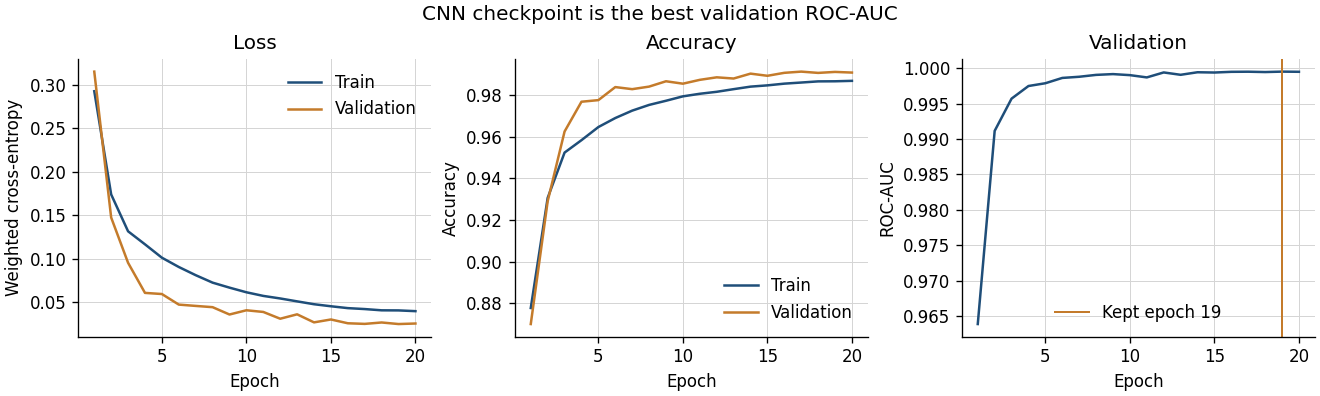

In [8]:
import json
import math
import os
from pathlib import Path
import shutil
import time
from io import BytesIO
import wave

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from IPython.display import Image, display
try:
    from datasets import Audio, load_dataset
except ImportError:
    import subprocess
    import sys
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "datasets"])
    from datasets import Audio, load_dataset
from torch import nn

SR = 16_000
WIN = SR
N_MELS = 128
N_FRAMES = 98
N_FFT = 400
HOP = 160
FMIN = 20.0
FMAX = 8_000.0
N_CLASSES = 2
SEED = 42
MAX_EPOCHS = 20
PATIENCE = 5
BATCH_SIZE = 64
LEARNING_RATE = 3e-4
WEIGHT_DECAY = 0.01
PROCESSED_DIR = Path.cwd() / "dataset2-processed"
FEATURES_DIR = Path.cwd() / "features-dataset2"
MODELS_DIR = Path.cwd() / "models"
TEMPORARY_CACHE = FEATURES_DIR / "cnn_train_logmel_run.npy"


class SpectrogramCNN(nn.Module):
    """Same three-layer CNN as section 7, so this cell can run after a kernel restart."""

    def __init__(self):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(1, 32, kernel_size=3, padding=1),
            nn.GELU(),
            nn.MaxPool2d(2),
            nn.Conv2d(32, 64, kernel_size=3, padding=1),
            nn.GELU(),
            nn.MaxPool2d(2),
            nn.Conv2d(64, 128, kernel_size=3, padding=1),
            nn.GELU(),
            nn.AdaptiveAvgPool2d(1),
        )
        self.head = nn.Linear(128, N_CLASSES)

    def forward(self, spectrogram):
        hidden = self.features(spectrogram.unsqueeze(1)).flatten(1)
        return self.head(hidden)


def n_parameters(module):
    return sum(parameter.numel() for parameter in module.parameters())


def read_pcm(blob):
    with wave.open(BytesIO(blob), "rb") as handle:
        if handle.getnchannels() != 1 or handle.getsampwidth() != 2 or handle.getframerate() != SR:
            raise ValueError("A window file is not mono 16-bit 16 kHz.")
        raw = handle.readframes(handle.getnframes())
    return np.frombuffer(raw, dtype="<i2").astype(np.float32) * np.float32(1.0 / 32768.0)


def mel_filterbank(sr, n_fft, n_mels, fmin, fmax):
    def hz_to_mel(hz):
        return 2595.0 * np.log10(1.0 + hz / 700.0)

    def mel_to_hz(mel):
        return 700.0 * (10.0 ** (mel / 2595.0) - 1.0)

    points = np.linspace(hz_to_mel(fmin), hz_to_mel(fmax), n_mels + 2)
    bins = np.floor((n_fft + 1) * mel_to_hz(points) / sr).astype(int)
    bank = np.zeros((n_mels, n_fft // 2 + 1), dtype=np.float32)
    for i in range(n_mels):
        left, center, right = int(bins[i]), int(bins[i + 1]), int(bins[i + 2])
        if center <= left:
            center = left + 1
        if right <= center:
            right = center + 1
        for j in range(left, center):
            if 0 <= j < bank.shape[1]:
                bank[i, j] = (j - left) / (center - left)
        for j in range(center, right):
            if 0 <= j < bank.shape[1]:
                bank[i, j] = (right - j) / (right - center)
    return bank


def log_mel_batch(batch, bank, stft_window):
    frames = np.lib.stride_tricks.sliding_window_view(batch, N_FFT, axis=1)[:, ::HOP, :]
    power = np.abs(np.fft.rfft(frames * stft_window, axis=-1)) ** 2
    mel = np.log(power @ bank.T + 1e-6)
    return mel.astype(np.float32).transpose(0, 2, 1)


def mask_spectrogram(spec):
    """Train-only mask. A masked cell is set to 0, the training mean after scaling."""
    spec = spec.clone()
    n_mels, n_frames = spec.shape
    for _ in range(2):
        width = int(torch.randint(0, 12, (1,)))
        start = int(torch.randint(0, n_mels - width + 1, (1,)))
        spec[start:start + width, :] = 0
    for _ in range(2):
        width = int(torch.randint(0, 8, (1,)))
        start = int(torch.randint(0, n_frames - width + 1, (1,)))
        spec[:, start:start + width] = 0
    return spec


def scores_from(labels, predicted, drone_probability):
    labels = np.asarray(labels)
    predicted = np.asarray(predicted)
    confusion = np.zeros((2, 2), dtype=int)
    for truth, guess in zip(labels, predicted):
        confusion[int(truth), int(guess)] += 1
    true_positive = confusion[1, 1]
    false_positive = confusion[0, 1]
    false_negative = confusion[1, 0]
    precision = true_positive / (true_positive + false_positive) if true_positive + false_positive else 0.0
    recall = true_positive / (true_positive + false_negative) if true_positive + false_negative else 0.0
    f1 = 2 * precision * recall / (precision + recall) if precision + recall else 0.0
    accuracy = (confusion[0, 0] + confusion[1, 1]) / confusion.sum()
    order = np.argsort(-np.asarray(drone_probability))
    ranked = labels[order]
    n_pos = max(int((labels == 1).sum()), 1)
    n_neg = max(int((labels == 0).sum()), 1)
    tpr = np.cumsum(ranked == 1) / n_pos
    fpr = np.cumsum(ranked == 0) / n_neg
    auc = float(np.trapezoid(np.r_[0.0, tpr], np.r_[0.0, fpr]))
    return {
        "accuracy": float(accuracy),
        "drone_precision": float(precision),
        "drone_recall": float(recall),
        "drone_f1": float(f1),
        "roc_auc": auc,
    }


def learning_rate(step, steps_per_epoch):
    warmup = steps_per_epoch
    total = MAX_EPOCHS * steps_per_epoch
    if step < warmup:
        return LEARNING_RATE * (step + 1) / warmup
    progress = min((step - warmup) / max(1, total - warmup), 1.0)
    return LEARNING_RATE * 0.5 * (1.0 + math.cos(math.pi * progress))


def show(fig):
    buf = BytesIO()
    fig.savefig(buf, format="png", dpi=120)
    display(Image(data=buf.getvalue()))
    plt.close(fig)


def set_seed(seed):
    np.random.seed(seed)
    torch.manual_seed(seed)


def load_saved_split(split_name, expected_labels):
    mel_path = FEATURES_DIR / f"{split_name}_logmel.npy"
    label_path = FEATURES_DIR / f"{split_name}_label.npy"
    mel = np.load(mel_path, mmap_mode="r")
    if mel.shape != (len(expected_labels), N_MELS, N_FRAMES):
        raise RuntimeError(f"{mel_path.name} shape is {mel.shape}, expected {(len(expected_labels), N_MELS, N_FRAMES)}.")
    if label_path.exists():
        labels = np.load(label_path)
        if labels.shape != (len(expected_labels),) or not np.array_equal(labels, expected_labels):
            raise RuntimeError(f"{label_path.name} does not match the {split_name} rows of the window list.")
    return mel, expected_labels.astype(np.int8)


set_seed(SEED)
probe = SpectrogramCNN()
if n_parameters(probe) != 92_930:
    raise RuntimeError(f"The CNN has {n_parameters(probe):,} parameters, expected 92,930.")
with torch.no_grad():
    probe_logits = probe(torch.zeros(2, N_MELS, N_FRAMES))
if tuple(probe_logits.shape) != (2, N_CLASSES):
    raise RuntimeError(f"Probe logit shape is {tuple(probe_logits.shape)}.")
del probe

windows = pd.read_csv(PROCESSED_DIR / "windows.csv")
if windows.groupby("group_id").split.nunique().max() != 1:
    raise RuntimeError("The window list places one file in two splits.")
held = {name: set(windows.loc[windows.split == name, "group_id"]) for name in ("train", "val", "test")}
overlap = len(held["train"] & held["val"]) + len(held["train"] & held["test"]) + len(held["val"] & held["test"])
if overlap:
    raise RuntimeError(f"Splits share {overlap} files.")
use = windows[windows.split.isin(["train", "val"])].reset_index(drop=True)
if (use.split == "test").any():
    raise RuntimeError("Test windows entered the training table.")

mel_mean = np.load(FEATURES_DIR / "train_logmel_mean.npy")
mel_std = np.load(FEATURES_DIR / "train_logmel_std.npy")
if mel_mean.shape != (N_MELS,) or mel_std.shape != (N_MELS,):
    raise RuntimeError("The training scale does not match 128 mel bins.")

saved_train = FEATURES_DIR / "train_logmel.npy"
saved_val = FEATURES_DIR / "val_logmel.npy"
used_disk_cache = False
loaded_saved = saved_train.exists() and saved_val.exists()
history = []
try:
    if loaded_saved:
        train_labels = windows.loc[windows.split == "train", "label"].to_numpy()
        val_labels = windows.loc[windows.split == "val", "label"].to_numpy()
        train_mel, train_y = load_saved_split("train", train_labels)
        val_mel, val_y = load_saved_split("val", val_labels)
        print(
            f"Loaded {len(train_y):,} training spectrograms and {len(val_y):,} validation spectrograms from {FEATURES_DIR}.",
            flush=True,
        )
        print("Test windows were not read.", flush=True)
    else:
        order = np.argsort(use.row_index.to_numpy(), kind="mergesort")
        row_ids = use.row_index.to_numpy()[order]
        starts = use.start_sample.to_numpy()[order]
        lengths = use.n_samples.to_numpy()[order]
        padded = use.padded.to_numpy()[order]
        splits = use.split.to_numpy()[order]
        labels = use.label.to_numpy()[order]
        slot_of = np.empty(len(order), dtype=np.int64)
        counts = {"train": 0, "val": 0}
        for index, split_name in enumerate(splits):
            slot_of[index] = counts[split_name]
            counts[split_name] += 1
        groups = {}
        for position, row_index in enumerate(row_ids):
            groups.setdefault(int(row_index), []).append(position)

        bank = mel_filterbank(SR, N_FFT, N_MELS, FMIN, FMAX)
        stft_window = np.hanning(N_FFT).astype(np.float32)

        def physical_ram():
            try:
                return os.sysconf("SC_PAGE_SIZE") * os.sysconf("SC_PHYS_PAGES")
            except (ValueError, OSError):
                return 0

        train_bytes = counts["train"] * N_MELS * N_FRAMES * np.dtype(np.float16).itemsize
        val_bytes = counts["val"] * N_MELS * N_FRAMES * np.dtype(np.float16).itemsize
        use_memory = torch.cuda.is_available() or physical_ram() > (train_bytes + val_bytes) * 2
        if use_memory:
            train_mel = np.empty((counts["train"], N_MELS, N_FRAMES), dtype=np.float16)
            print("Training spectrograms will stay in memory.", flush=True)
        else:
            need_bytes = train_bytes + 2 * 1024**3
            free_bytes = shutil.disk_usage(FEATURES_DIR).free
            if free_bytes < need_bytes:
                raise RuntimeError(
                    f"Need {need_bytes / 1e9:.1f} GB free for the temporary training cache, found {free_bytes / 1e9:.1f} GB."
                )
            if TEMPORARY_CACHE.exists():
                TEMPORARY_CACHE.unlink()
            train_mel = np.lib.format.open_memmap(
                TEMPORARY_CACHE, mode="w+", dtype=np.float16, shape=(counts["train"], N_MELS, N_FRAMES)
            )
            used_disk_cache = True
            print("Training spectrograms will use a temporary disk cache.", flush=True)
        val_mel = np.empty((counts["val"], N_MELS, N_FRAMES), dtype=np.float16)
        train_y = np.full(counts["train"], -1, dtype=np.int8)
        val_y = np.full(counts["val"], -1, dtype=np.int8)

        dataset = load_dataset("Z121mm/drone-audio-detection-samples")["train"].cast_column("audio", Audio(decode=False))
        filled = {"train": 0, "val": 0}
        n_files = 0
        for row_index, row in enumerate(dataset):
            positions = groups.get(row_index)
            if positions is None:
                continue
            samples = read_pcm(row["audio"]["bytes"])
            waves = []
            for position in positions:
                start = int(starts[position])
                length = int(lengths[position])
                piece = samples[start:start + length]
                if bool(padded[position]):
                    waveform = np.zeros(WIN, dtype=np.float32)
                    waveform[:piece.size] = piece
                else:
                    waveform = np.ascontiguousarray(piece)
                waves.append(waveform)
            specs = log_mel_batch(np.stack(waves), bank, stft_window)
            scaled = (specs - mel_mean[None, :, None]) / mel_std[None, :, None]
            split_name = str(splits[positions[0]])
            start_slot = int(slot_of[positions[0]])
            if int(slot_of[positions[-1]]) != start_slot + len(positions) - 1:
                raise RuntimeError(f"Windows of row {row_index} are not contiguous in the cache.")
            target = train_mel if split_name == "train" else val_mel
            target_y = train_y if split_name == "train" else val_y
            target[start_slot:start_slot + len(positions)] = scaled.astype(np.float16)
            target_y[start_slot:start_slot + len(positions)] = labels[positions]
            filled[split_name] += len(positions)
            n_files += 1
            if n_files % 20000 == 0:
                print(f"cached {n_files:,} train and validation files", flush=True)
        del dataset
        if hasattr(train_mel, "flush"):
            train_mel.flush()
        if filled["train"] != counts["train"] or filled["val"] != counts["val"]:
            raise RuntimeError(f"Cached {filled}, expected {counts}.")
        if (train_y < 0).any() or (val_y < 0).any():
            raise RuntimeError("A training or validation window was not given a label.")
        print(
            f"Cached {counts['train']:,} training spectrograms and {counts['val']:,} validation spectrograms.",
            flush=True,
        )
        print("Test windows were not read.", flush=True)

    if torch.cuda.is_available():
        device = torch.device("cuda")
    elif torch.backends.mps.is_available():
        device = torch.device("mps")
    else:
        device = torch.device("cpu")
    use_bf16 = device.type == "cuda" and torch.cuda.is_bf16_supported()
    set_seed(SEED)
    model = SpectrogramCNN().to(device)
    train_counts = np.bincount(train_y, minlength=2).astype(np.float32)
    class_weight = torch.tensor(train_counts.sum() / (2.0 * train_counts), dtype=torch.float32, device=device)
    stored_weight = json.loads((PROCESSED_DIR / "class_weights.json").read_text())
    if abs(class_weight[0].item() - stored_weight["no_drone"]) > 1e-4 or abs(class_weight[1].item() - stored_weight["drone"]) > 1e-4:
        raise RuntimeError("The training class weight does not match class_weights.json.")
    criterion = nn.CrossEntropyLoss(weight=class_weight)
    optimizer = torch.optim.AdamW(model.parameters(), lr=LEARNING_RATE, weight_decay=WEIGHT_DECAY)
    steps_per_epoch = math.ceil(len(train_y) / BATCH_SIZE)
    global_step = 0
    best_auc = -1.0
    best_epoch = 0
    best_state = None
    wait = 0

    val_labels_fixed = val_y.astype(np.int64)
    for epoch in range(1, MAX_EPOCHS + 1):
        started = time.perf_counter()
        model.train()
        total_loss = 0.0
        correct = 0
        seen = 0
        permutation = np.random.default_rng(SEED + epoch).permutation(len(train_y))
        for start in range(0, len(train_y), BATCH_SIZE):
            choice = permutation[start:start + BATCH_SIZE]
            for group in optimizer.param_groups:
                group["lr"] = learning_rate(global_step, steps_per_epoch)
            spectrogram = torch.from_numpy(np.asarray(train_mel[choice], dtype=np.float32))
            spectrogram = torch.stack([mask_spectrogram(item) for item in spectrogram]).to(device)
            label = torch.from_numpy(train_y[choice].astype(np.int64)).to(device)
            optimizer.zero_grad(set_to_none=True)
            with torch.autocast(device_type=device.type, dtype=torch.bfloat16, enabled=use_bf16):
                logits = model(spectrogram)
                loss = criterion(logits, label)
            loss.backward()
            nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            optimizer.step()
            global_step += 1
            total_loss += loss.item() * len(label)
            correct += int((logits.argmax(dim=1) == label).sum().item())
            seen += len(label)
        train_loss = total_loss / seen
        train_accuracy = correct / seen

        model.eval()
        val_loss_total = 0.0
        val_seen = 0
        val_predicted = []
        val_probability = []
        with torch.no_grad():
            for start in range(0, len(val_y), BATCH_SIZE):
                spectrogram = torch.from_numpy(np.asarray(val_mel[start:start + BATCH_SIZE], dtype=np.float32)).to(device)
                label = torch.from_numpy(val_labels_fixed[start:start + BATCH_SIZE]).to(device)
                with torch.autocast(device_type=device.type, dtype=torch.bfloat16, enabled=use_bf16):
                    logits = model(spectrogram)
                    loss = criterion(logits, label)
                val_loss_total += loss.item() * len(label)
                val_seen += len(label)
                val_predicted.append(logits.argmax(dim=1).cpu().numpy())
                val_probability.append(torch.softmax(logits.float(), dim=1)[:, 1].cpu().numpy())
        val_scores = scores_from(val_labels_fixed, np.concatenate(val_predicted), np.concatenate(val_probability))
        val_loss = val_loss_total / val_seen
        improved = val_scores["roc_auc"] > best_auc
        if improved:
            best_auc = val_scores["roc_auc"]
            best_epoch = epoch
            best_state = {name: value.detach().cpu().clone() for name, value in model.state_dict().items()}
            wait = 0
        else:
            wait += 1
        history.append({
            "epoch": epoch,
            "train_loss": train_loss,
            "train_accuracy": train_accuracy,
            "val_loss": val_loss,
            "val_accuracy": val_scores["accuracy"],
            "val_roc_auc": val_scores["roc_auc"],
            "val_drone_f1": val_scores["drone_f1"],
            "kept": improved,
        })
        mark = "  kept" if improved else ""
        print(
            f"epoch {epoch:2d}  train loss {train_loss:.3f}  val loss {val_loss:.3f}  "
            f"val accuracy {val_scores['accuracy']:.3f}  val ROC-AUC {val_scores['roc_auc']:.3f}  "
            f"val drone F1 {val_scores['drone_f1']:.3f}{mark}  ({time.perf_counter() - started:.0f}s)",
            flush=True,
        )
        if wait >= PATIENCE:
            print(f"Stopped after epoch {epoch}. Validation ROC-AUC did not improve for {PATIENCE} epochs.")
            break

    if best_state is None:
        raise RuntimeError("Training did not keep a checkpoint.")
    model.load_state_dict(best_state)
    MODELS_DIR.mkdir(parents=True, exist_ok=True)
    checkpoint_path = MODELS_DIR / "spectrogram_cnn_dataset2.pt"
    torch.save({
        "state_dict": best_state,
        "epoch": best_epoch,
        "val_roc_auc": best_auc,
        "class_weight": class_weight.detach().cpu(),
        "config": {
            "model": "SpectrogramCNN",
            "channels": [32, 64, 128],
            "n_mels": N_MELS,
            "n_frames": N_FRAMES,
            "n_classes": N_CLASSES,
            "learning_rate": LEARNING_RATE,
            "weight_decay": WEIGHT_DECAY,
            "batch_size": BATCH_SIZE,
        },
    }, checkpoint_path)
finally:
    cache = globals().get("train_mel")
    if used_disk_cache and cache is not None:
        mapping = getattr(cache, "_mmap", None)
        if mapping is not None:
            mapping.close()
        del cache
        globals().pop("train_mel", None)
    if used_disk_cache and TEMPORARY_CACHE.exists():
        TEMPORARY_CACHE.unlink()

if not history:
    raise RuntimeError("Training produced no epochs.")
history_frame = pd.DataFrame(history)
display(history_frame.style.format({
    "train_loss": "{:.3f}",
    "train_accuracy": "{:.3f}",
    "val_loss": "{:.3f}",
    "val_accuracy": "{:.3f}",
    "val_roc_auc": "{:.3f}",
    "val_drone_f1": "{:.3f}",
}).hide(axis="index"))
if device.type == "cuda":
    print(f"Device: {torch.cuda.get_device_name(0)}")
else:
    print(f"Device: {device.type}")
print(f"Precision: {'bfloat16' if use_bf16 else 'float32'}")
print(f"Parameters: {n_parameters(model):,}")
print(f"Training windows: {len(train_y):,}  ({int(train_counts[1]):,} drone, {int(train_counts[0]):,} no drone)")
print(f"Validation windows: {len(val_y):,}")
print(f"Class weights from the training counts: no drone {class_weight[0].item():.3f}, drone {class_weight[1].item():.3f}")
print(f"File overlap between train, validation, and test: {overlap}")
print(f"Kept epoch {best_epoch} with validation ROC-AUC {best_auc:.3f}")
print(f"Saved checkpoint: {checkpoint_path}")
if used_disk_cache:
    print("Temporary training spectrograms deleted.")

fig, axes = plt.subplots(1, 3, figsize=(11, 3.3), layout="constrained")
axes[0].plot(history_frame.epoch, history_frame.train_loss, label="Train", color="#1f4e79")
axes[0].plot(history_frame.epoch, history_frame.val_loss, label="Validation", color="#c47b2b")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Weighted cross-entropy")
axes[0].set_title("Loss")
axes[0].legend()
axes[1].plot(history_frame.epoch, history_frame.train_accuracy, label="Train", color="#1f4e79")
axes[1].plot(history_frame.epoch, history_frame.val_accuracy, label="Validation", color="#c47b2b")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Accuracy")
axes[1].set_title("Accuracy")
axes[1].legend()
axes[2].plot(history_frame.epoch, history_frame.val_roc_auc, color="#1f4e79")
axes[2].axvline(best_epoch, color="#c47b2b", linewidth=1.2, label=f"Kept epoch {best_epoch}")
axes[2].set_xlabel("Epoch")
axes[2].set_ylabel("ROC-AUC")
axes[2].set_title("Validation")
axes[2].legend()
fig.suptitle("CNN checkpoint is the best validation ROC-AUC", fontsize=12)
show(fig)


## 9. CNN evaluation

Load `models/spectrogram_cnn_dataset2.pt`. This cell does not train. If `val_logmel.npy` and `test_logmel.npy` are in `features-dataset2/`, load those. If they are absent, rebuild the validation and test spectrograms from the window list and apply the saved training scale. Training audio is not read. Score the test split once.

Report accuracy, drone precision, recall, F1, ROC-AUC, and average precision, next to the majority class taken from the training windows. Plot the ROC curve, the precision-recall curve, the confusion matrix, and the true-positive, true-negative, false-positive, and false-negative counts.

Choose the 1% and 5% false-alarm thresholds on the saved validation features, then apply those two thresholds to the test set and report the detection rate. Show a few test windows the CNN got wrong.


Resolving data files:   0%|          | 0/39 [00:00<?, ?it/s]

Resolving data files:   0%|          | 0/39 [00:00<?, ?it/s]

read 20,000 validation and test files
read 40,000 validation and test files
Rebuilt 57,004 validation spectrograms and 57,015 test spectrograms.
Training audio was not read.


model,accuracy,drone_precision,drone_recall,drone_f1,roc_auc,average_precision
Always drone,0.503,0.503,1.000,0.669,0.500,0.503
Spectrogram CNN,0.993,0.995,0.990,0.993,0.999,0.999


validation_false_alarm,threshold,test_detection_rate,test_false_alarm_rate
1%,0.315,0.993,0.008
5%,0.029,0.998,0.049


Device: NVIDIA A100-SXM4-40GB
Checkpoint epoch 19, validation ROC-AUC 1.000
Test windows: 57,015  (28,681 drone, 28,334 no drone)
Test weighted loss: 0.024
File overlap between train, validation, and test: 0
Thresholds were chosen on validation and applied once to the test set.
This is the only score of the test split.


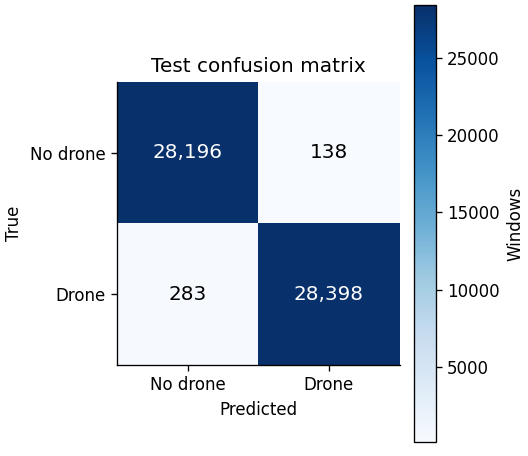

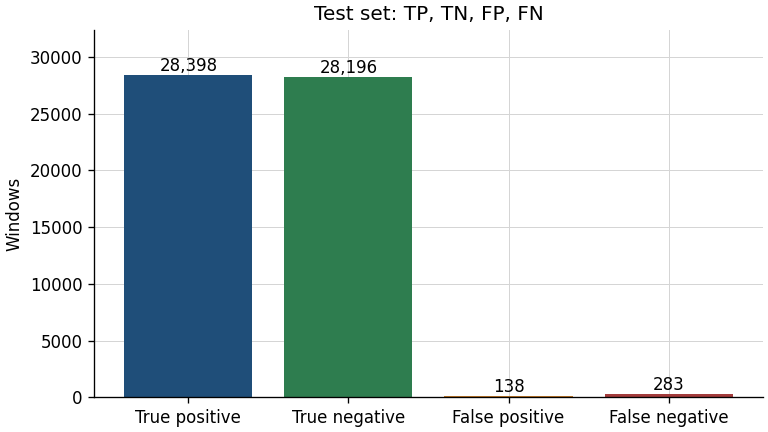

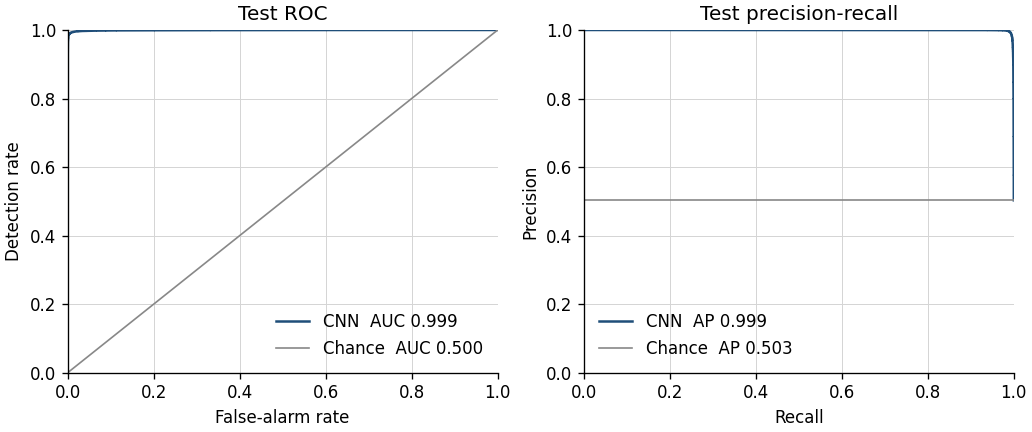

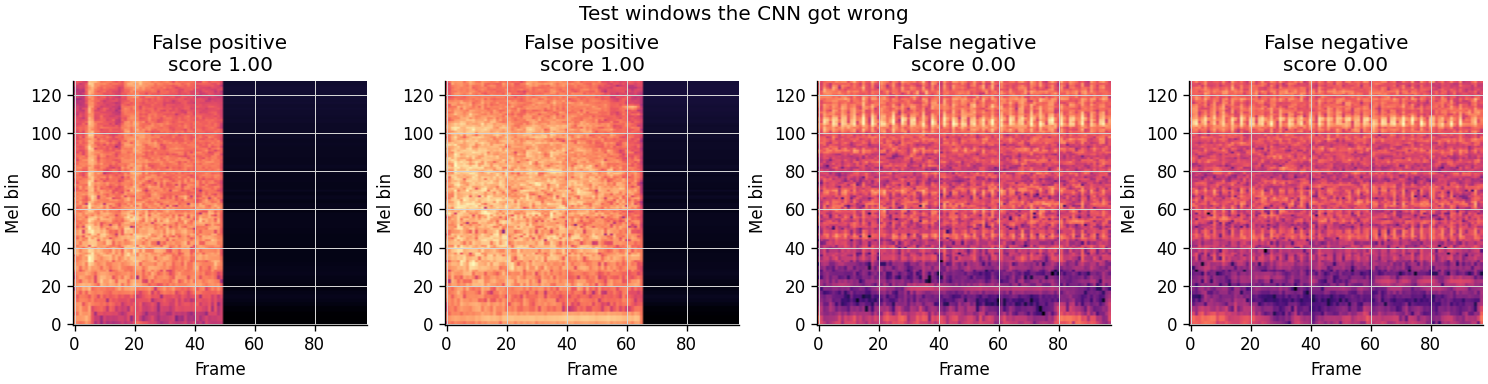

In [9]:
from pathlib import Path
from io import BytesIO
import wave

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from IPython.display import Image, display
from torch import nn

try:
    from datasets import Audio, load_dataset
except ImportError:
    import subprocess
    import sys
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "datasets"])
    from datasets import Audio, load_dataset

SR = 16_000
WIN = SR
N_MELS = 128
N_FRAMES = 98
N_FFT = 400
HOP = 160
FMIN = 20.0
FMAX = 8_000.0
N_CLASSES = 2
BATCH_SIZE = 64
LABEL = {0: "No drone", 1: "Drone"}
PROCESSED_DIR = Path.cwd() / "dataset2-processed"
FEATURES_DIR = Path.cwd() / "features-dataset2"
CHECKPOINT_PATH = Path.cwd() / "models" / "spectrogram_cnn_dataset2.pt"


class SpectrogramCNN(nn.Module):
    """Same three-layer CNN as section 8, loaded from the saved checkpoint."""

    def __init__(self):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(1, 32, kernel_size=3, padding=1),
            nn.GELU(),
            nn.MaxPool2d(2),
            nn.Conv2d(32, 64, kernel_size=3, padding=1),
            nn.GELU(),
            nn.MaxPool2d(2),
            nn.Conv2d(64, 128, kernel_size=3, padding=1),
            nn.GELU(),
            nn.AdaptiveAvgPool2d(1),
        )
        self.head = nn.Linear(128, N_CLASSES)

    def forward(self, spectrogram):
        hidden = self.features(spectrogram.unsqueeze(1)).flatten(1)
        return self.head(hidden)


def read_pcm(blob):
    with wave.open(BytesIO(blob), "rb") as handle:
        if handle.getnchannels() != 1 or handle.getsampwidth() != 2 or handle.getframerate() != SR:
            raise ValueError("A window file is not mono 16-bit 16 kHz.")
        raw = handle.readframes(handle.getnframes())
    return np.frombuffer(raw, dtype="<i2").astype(np.float32) * np.float32(1.0 / 32768.0)


def mel_filterbank(sr, n_fft, n_mels, fmin, fmax):
    def hz_to_mel(hz):
        return 2595.0 * np.log10(1.0 + hz / 700.0)

    def mel_to_hz(mel):
        return 700.0 * (10.0 ** (mel / 2595.0) - 1.0)

    points = np.linspace(hz_to_mel(fmin), hz_to_mel(fmax), n_mels + 2)
    bins = np.floor((n_fft + 1) * mel_to_hz(points) / sr).astype(int)
    bank = np.zeros((n_mels, n_fft // 2 + 1), dtype=np.float32)
    for i in range(n_mels):
        left, center, right = int(bins[i]), int(bins[i + 1]), int(bins[i + 2])
        if center <= left:
            center = left + 1
        if right <= center:
            right = center + 1
        for j in range(left, center):
            if 0 <= j < bank.shape[1]:
                bank[i, j] = (j - left) / (center - left)
        for j in range(center, right):
            if 0 <= j < bank.shape[1]:
                bank[i, j] = (right - j) / (right - center)
    return bank


def log_mel_batch(batch, bank, stft_window):
    frames = np.lib.stride_tricks.sliding_window_view(batch, N_FFT, axis=1)[:, ::HOP, :]
    power = np.abs(np.fft.rfft(frames * stft_window, axis=-1)) ** 2
    mel = np.log(power @ bank.T + 1e-6)
    return mel.astype(np.float32).transpose(0, 2, 1)


def average_precision(labels, probability):
    labels = np.asarray(labels)
    order = np.argsort(-np.asarray(probability))
    ranked = labels[order]
    hits = ranked == 1
    n_pos = max(int(hits.sum()), 1)
    precision = np.cumsum(hits) / np.arange(1, len(ranked) + 1)
    return float(precision[hits].sum() / n_pos)


def rates_at_threshold(labels, probability, threshold):
    labels = np.asarray(labels)
    predicted = (np.asarray(probability) >= threshold).astype(np.int64)
    positives = predicted == 1
    negatives = ~positives
    true_pos = int(((labels == 1) & positives).sum())
    false_pos = int(((labels == 0) & positives).sum())
    false_neg = int(((labels == 1) & negatives).sum())
    true_neg = int(((labels == 0) & negatives).sum())
    n_pos = max(true_pos + false_neg, 1)
    n_neg = max(true_neg + false_pos, 1)
    return {
        "detection_rate": true_pos / n_pos,
        "false_alarm_rate": false_pos / n_neg,
        "threshold": float(threshold),
    }


def threshold_at_false_alarm(labels, probability, target):
    labels = np.asarray(labels)
    probability = np.asarray(probability)
    order = np.argsort(-probability)
    ranked = labels[order]
    scores = probability[order]
    n_neg = max(int((labels == 0).sum()), 1)
    false_alarm = np.cumsum(ranked == 0) / n_neg
    allowed = np.flatnonzero(false_alarm <= target)
    if allowed.size == 0:
        return float(scores[0] + 1.0)
    return float(scores[allowed[-1]])


def show(fig):
    buf = BytesIO()
    fig.savefig(buf, format="png", dpi=120)
    display(Image(data=buf.getvalue()))
    plt.close(fig)


def load_saved_split(split_name, expected_labels):
    mel_path = FEATURES_DIR / f"{split_name}_logmel.npy"
    label_path = FEATURES_DIR / f"{split_name}_label.npy"
    mel = np.load(mel_path, mmap_mode="r")
    if mel.shape != (len(expected_labels), N_MELS, N_FRAMES):
        raise RuntimeError(
            f"{mel_path.name} shape is {mel.shape}, expected {(len(expected_labels), N_MELS, N_FRAMES)}."
        )
    if label_path.exists():
        labels = np.load(label_path)
        if labels.shape != (len(expected_labels),) or not np.array_equal(labels, expected_labels):
            raise RuntimeError(f"{label_path.name} does not match the {split_name} rows of the window list.")
    return mel, expected_labels.astype(np.int8)


if not CHECKPOINT_PATH.exists():
    raise RuntimeError(
        "No CNN checkpoint yet. Run section 8 first. This cell scores the saved model and does not train."
    )

windows = pd.read_csv(PROCESSED_DIR / "windows.csv")
if windows.groupby("group_id").split.nunique().max() != 1:
    raise RuntimeError("The window list places one file in two splits.")
held = {name: set(windows.loc[windows.split == name, "group_id"]) for name in ("train", "val", "test")}
overlap = len(held["train"] & held["val"]) + len(held["train"] & held["test"]) + len(held["val"] & held["test"])
if overlap:
    raise RuntimeError(f"Splits share {overlap} files.")
train_counts = np.bincount(windows.loc[windows.split == "train", "label"], minlength=2)
majority = int(np.argmax(train_counts))

saved_val = FEATURES_DIR / "val_logmel.npy"
saved_test = FEATURES_DIR / "test_logmel.npy"
if saved_val.exists() and saved_test.exists():
    store = {}
    store_y = {}
    for split_name in ("val", "test"):
        expected = windows.loc[windows.split == split_name, "label"].to_numpy()
        store[split_name], store_y[split_name] = load_saved_split(split_name, expected)
    print(
        f"Loaded {len(store_y['val']):,} validation spectrograms and {len(store_y['test']):,} test spectrograms.",
        flush=True,
    )
    print("Training audio was not read.", flush=True)
else:
    use = windows[windows.split.isin(["val", "test"])].reset_index(drop=True)
    if (use.split == "train").any():
        raise RuntimeError("A training window entered the evaluation table.")
    order = np.argsort(use.row_index.to_numpy(), kind="mergesort")
    row_ids = use.row_index.to_numpy()[order]
    starts = use.start_sample.to_numpy()[order]
    lengths = use.n_samples.to_numpy()[order]
    padded = use.padded.to_numpy()[order]
    splits = use.split.to_numpy()[order]
    labels_all = use.label.to_numpy()[order]
    slot_of = np.empty(len(order), dtype=np.int64)
    counts = {"val": 0, "test": 0}
    for index, split_name in enumerate(splits):
        slot_of[index] = counts[split_name]
        counts[split_name] += 1
    groups = {}
    for position, row_index in enumerate(row_ids):
        groups.setdefault(int(row_index), []).append(position)

    mel_mean = np.load(FEATURES_DIR / "train_logmel_mean.npy")
    mel_std = np.load(FEATURES_DIR / "train_logmel_std.npy")
    bank = mel_filterbank(SR, N_FFT, N_MELS, FMIN, FMAX)
    stft_window = np.hanning(N_FFT).astype(np.float32)
    store = {
        "val": np.empty((counts["val"], N_MELS, N_FRAMES), dtype=np.float16),
        "test": np.empty((counts["test"], N_MELS, N_FRAMES), dtype=np.float16),
    }
    store_y = {
        "val": np.full(counts["val"], -1, dtype=np.int8),
        "test": np.full(counts["test"], -1, dtype=np.int8),
    }

    dataset = load_dataset("Z121mm/drone-audio-detection-samples")["train"].cast_column("audio", Audio(decode=False))
    filled = {"val": 0, "test": 0}
    n_files = 0
    for row_index, row in enumerate(dataset):
        positions = groups.get(row_index)
        if positions is None:
            continue
        samples = read_pcm(row["audio"]["bytes"])
        waves = []
        for position in positions:
            start = int(starts[position])
            length = int(lengths[position])
            piece = samples[start:start + length]
            if bool(padded[position]):
                waveform = np.zeros(WIN, dtype=np.float32)
                waveform[:piece.size] = piece
            else:
                waveform = np.ascontiguousarray(piece)
            waves.append(waveform)
        specs = log_mel_batch(np.stack(waves), bank, stft_window)
        scaled = (specs - mel_mean[None, :, None]) / mel_std[None, :, None]
        split_name = str(splits[positions[0]])
        start_slot = int(slot_of[positions[0]])
        store[split_name][start_slot:start_slot + len(positions)] = scaled.astype(np.float16)
        store_y[split_name][start_slot:start_slot + len(positions)] = labels_all[positions]
        filled[split_name] += len(positions)
        n_files += 1
        if n_files % 20000 == 0:
            print(f"read {n_files:,} validation and test files", flush=True)
    del dataset
    if filled != counts or (store_y["test"] < 0).any() or (store_y["val"] < 0).any():
        raise RuntimeError(f"Built {filled}, expected {counts}.")
    print(
        f"Rebuilt {counts['val']:,} validation spectrograms and {counts['test']:,} test spectrograms.",
        flush=True,
    )
    print("Training audio was not read.", flush=True)

if torch.cuda.is_available():
    device = torch.device("cuda")
elif torch.backends.mps.is_available():
    device = torch.device("mps")
else:
    device = torch.device("cpu")
checkpoint = torch.load(CHECKPOINT_PATH, map_location="cpu", weights_only=False)
if checkpoint.get("config", {}).get("model") not in (None, "SpectrogramCNN"):
    raise RuntimeError(f"{CHECKPOINT_PATH.name} is not the CNN checkpoint.")
model = SpectrogramCNN().to(device)
model.load_state_dict(checkpoint["state_dict"])
model.eval()
class_weight = checkpoint["class_weight"].to(device)
criterion = nn.CrossEntropyLoss(weight=class_weight)


@torch.no_grad()
def predict(mel, labels):
    labels = np.asarray(labels)
    loss_total = 0.0
    seen = 0
    predicted = []
    probability = []
    for start in range(0, len(labels), BATCH_SIZE):
        spectrogram = torch.from_numpy(np.asarray(mel[start:start + BATCH_SIZE], dtype=np.float32)).to(device)
        label = torch.from_numpy(labels[start:start + BATCH_SIZE].astype(np.int64)).to(device)
        logits = model(spectrogram)
        loss = criterion(logits, label)
        loss_total += loss.item() * len(label)
        seen += len(label)
        predicted.append(logits.argmax(dim=1).cpu().numpy())
        probability.append(torch.softmax(logits.float(), dim=1)[:, 1].cpu().numpy())
    return loss_total / seen, labels.astype(np.int64), np.concatenate(predicted), np.concatenate(probability)


val_loss, val_labels, val_predicted, val_probability = predict(store["val"], store_y["val"])
thresholds = {
    0.01: threshold_at_false_alarm(val_labels, val_probability, 0.01),
    0.05: threshold_at_false_alarm(val_labels, val_probability, 0.05),
}
test_loss, test_labels, test_predicted, test_probability = predict(store["test"], store_y["test"])
del store["val"], store_y["val"]

true_pos = int(((test_labels == 1) & (test_predicted == 1)).sum())
false_pos = int(((test_labels == 0) & (test_predicted == 1)).sum())
false_neg = int(((test_labels == 1) & (test_predicted == 0)).sum())
true_neg = int(((test_labels == 0) & (test_predicted == 0)).sum())
precision = true_pos / (true_pos + false_pos) if true_pos + false_pos else 0.0
recall = true_pos / (true_pos + false_neg) if true_pos + false_neg else 0.0
f1 = 2 * precision * recall / (precision + recall) if precision + recall else 0.0
accuracy = (true_pos + true_neg) / len(test_labels)
order = np.argsort(-test_probability)
ranked = test_labels[order]
n_pos = max(int((test_labels == 1).sum()), 1)
n_neg = max(int((test_labels == 0).sum()), 1)
tpr = np.cumsum(ranked == 1) / n_pos
fpr = np.cumsum(ranked == 0) / n_neg
roc_auc = float(np.trapezoid(np.r_[0.0, tpr], np.r_[0.0, fpr]))
pr_auc = average_precision(test_labels, test_probability)

majority_predicted = np.full(len(test_labels), majority, dtype=np.int64)
maj_tp = int(((test_labels == 1) & (majority_predicted == 1)).sum())
maj_fp = int(((test_labels == 0) & (majority_predicted == 1)).sum())
maj_fn = int(((test_labels == 1) & (majority_predicted == 0)).sum())
maj_precision = maj_tp / (maj_tp + maj_fp) if maj_tp + maj_fp else 0.0
maj_recall = maj_tp / (maj_tp + maj_fn) if maj_tp + maj_fn else 0.0
maj_f1 = 2 * maj_precision * maj_recall / (maj_precision + maj_recall) if maj_precision + maj_recall else 0.0
chance_ap = float((test_labels == 1).mean())

comparison = pd.DataFrame([
    {
        "model": f"Always {LABEL[majority].lower()}",
        "accuracy": float((majority_predicted == test_labels).mean()),
        "drone_precision": maj_precision,
        "drone_recall": maj_recall,
        "drone_f1": maj_f1,
        "roc_auc": 0.5,
        "average_precision": chance_ap,
    },
    {
        "model": "Spectrogram CNN",
        "accuracy": accuracy,
        "drone_precision": precision,
        "drone_recall": recall,
        "drone_f1": f1,
        "roc_auc": roc_auc,
        "average_precision": pr_auc,
    },
])
display(comparison.style.format({
    "accuracy": "{:.3f}",
    "drone_precision": "{:.3f}",
    "drone_recall": "{:.3f}",
    "drone_f1": "{:.3f}",
    "roc_auc": "{:.3f}",
    "average_precision": "{:.3f}",
}).hide(axis="index"))

operating = []
for target, threshold in thresholds.items():
    measured = rates_at_threshold(test_labels, test_probability, threshold)
    operating.append({
        "validation_false_alarm": target,
        "threshold": measured["threshold"],
        "test_detection_rate": measured["detection_rate"],
        "test_false_alarm_rate": measured["false_alarm_rate"],
    })
operating_frame = pd.DataFrame(operating)
display(operating_frame.style.format({
    "validation_false_alarm": "{:.0%}",
    "threshold": "{:.3f}",
    "test_detection_rate": "{:.3f}",
    "test_false_alarm_rate": "{:.3f}",
}).hide(axis="index"))
if device.type == "cuda":
    print(f"Device: {torch.cuda.get_device_name(0)}")
else:
    print(f"Device: {device.type}")
print(f"Checkpoint epoch {checkpoint['epoch']}, validation ROC-AUC {checkpoint['val_roc_auc']:.3f}")
print(f"Test windows: {len(test_labels):,}  ({int((test_labels == 1).sum()):,} drone, {int((test_labels == 0).sum()):,} no drone)")
print(f"Test weighted loss: {test_loss:.3f}")
print(f"File overlap between train, validation, and test: {overlap}")
print("Thresholds were chosen on validation and applied once to the test set.")
print("This is the only score of the test split.")

confusion = np.array([[true_neg, false_pos], [false_neg, true_pos]])
fig, ax = plt.subplots(figsize=(4.4, 3.8), layout="constrained")
image = ax.imshow(confusion, cmap="Blues")
ax.grid(False)
ax.set_xticks([0, 1])
ax.set_xticklabels(["No drone", "Drone"])
ax.set_yticks([0, 1])
ax.set_yticklabels(["No drone", "Drone"])
ax.set_xlabel("Predicted")
ax.set_ylabel("True")
ax.set_title("Test confusion matrix")
for row in range(2):
    for col in range(2):
        color = "white" if confusion[row, col] > confusion.max() / 2 else "black"
        ax.text(col, row, f"{confusion[row, col]:,}", ha="center", va="center", color=color, fontsize=12)
fig.colorbar(image, ax=ax, label="Windows")
show(fig)

outcome = {
    "True positive": true_pos,
    "True negative": true_neg,
    "False positive": false_pos,
    "False negative": false_neg,
}
fig, ax = plt.subplots(figsize=(6.4, 3.6), layout="constrained")
bars = ax.bar(list(outcome), list(outcome.values()), color=["#1f4e79", "#2e7d4f", "#c47b2b", "#a33b3b"])
ax.set_ylabel("Windows")
ax.set_title("Test set: TP, TN, FP, FN")
ax.set_ylim(0, max(outcome.values()) * 1.14)
for bar, value in zip(bars, outcome.values()):
    ax.text(bar.get_x() + bar.get_width() / 2, value, f"{value:,}", ha="center", va="bottom", fontsize=10)
show(fig)

precision_curve = np.cumsum(ranked == 1) / np.arange(1, len(ranked) + 1)
recall_curve = np.cumsum(ranked == 1) / n_pos
fig, axes = plt.subplots(1, 2, figsize=(8.6, 3.6), layout="constrained")
axes[0].plot(np.r_[0.0, fpr], np.r_[0.0, tpr], color="#1f4e79", label=f"CNN  AUC {roc_auc:.3f}")
axes[0].plot([0, 1], [0, 1], color="#888888", linewidth=1, label="Chance  AUC 0.500")
axes[0].set_xlabel("False-alarm rate")
axes[0].set_ylabel("Detection rate")
axes[0].set_title("Test ROC")
axes[0].set_xlim(0, 1)
axes[0].set_ylim(0, 1)
axes[0].legend(loc="lower right")
axes[1].plot(np.r_[0.0, recall_curve], np.r_[1.0, precision_curve], color="#1f4e79", label=f"CNN  AP {pr_auc:.3f}")
axes[1].axhline(chance_ap, color="#888888", linewidth=1, label=f"Chance  AP {chance_ap:.3f}")
axes[1].set_xlabel("Recall")
axes[1].set_ylabel("Precision")
axes[1].set_title("Test precision-recall")
axes[1].set_xlim(0, 1)
axes[1].set_ylim(0, 1)
axes[1].legend(loc="lower left")
show(fig)

false_pos_index = np.flatnonzero((test_labels == 0) & (test_predicted == 1))
false_neg_index = np.flatnonzero((test_labels == 1) & (test_predicted == 0))
false_pos_index = false_pos_index[np.argsort(-test_probability[false_pos_index])][:2]
false_neg_index = false_neg_index[np.argsort(test_probability[false_neg_index])][:2]
chosen = [(int(index), "False positive") for index in false_pos_index] + [
    (int(index), "False negative") for index in false_neg_index
]
if chosen:
    fig, axes = plt.subplots(1, len(chosen), figsize=(3.1 * len(chosen), 3.2), layout="constrained", squeeze=False)
    for ax, (index, kind) in zip(axes[0], chosen):
        ax.imshow(np.asarray(store["test"][index], dtype=np.float32), origin="lower", aspect="auto", cmap="magma")
        ax.set_title(f"{kind}\nscore {test_probability[index]:.2f}")
        ax.set_xlabel("Frame")
        ax.set_ylabel("Mel bin")
    fig.suptitle("Test windows the CNN got wrong", fontsize=12)
    show(fig)
else:
    print("The argmax rule made no false positives or false negatives on the test set.")
del store


In [10]:
import json
import shutil
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
import torch

try:
    from google.colab import auth
except ImportError as error:
    raise RuntimeError("Run this cell on Colab after section 9. It uploads the CNN results to Drive.") from error

from googleapiclient.discovery import build
from googleapiclient.http import MediaFileUpload
import google.auth

DRIVE_FOLDER_ID = "1dVY2ZdOB0PYWgS33dMi-UQLXh0woGkZB"
CHECKPOINT_PATH = Path.cwd() / "models" / "spectrogram_cnn_dataset2.pt"
RESULTS_DIR = Path.cwd() / "models" / "cnn_dataset2_results"


def require(name):
    if name not in globals():
        return None
    return globals()[name]


def save_figure(fig, path):
    fig.savefig(path, format="png", dpi=120)
    plt.close(fig)


if not CHECKPOINT_PATH.exists():
    raise RuntimeError("No CNN checkpoint yet. Run section 8 first.")

RESULTS_DIR.mkdir(parents=True, exist_ok=True)
shutil.copy2(CHECKPOINT_PATH, RESULTS_DIR / CHECKPOINT_PATH.name)
checkpoint = torch.load(CHECKPOINT_PATH, map_location="cpu", weights_only=False)

history_frame = require("history_frame")
if isinstance(history_frame, pd.DataFrame):
    history_frame.to_csv(RESULTS_DIR / "cnn_training_history.csv", index=False)
    best_epoch = int(checkpoint["epoch"])
    fig, axes = plt.subplots(1, 3, figsize=(11, 3.3), layout="constrained")
    axes[0].plot(history_frame.epoch, history_frame.train_loss, label="Train", color="#1f4e79")
    axes[0].plot(history_frame.epoch, history_frame.val_loss, label="Validation", color="#c47b2b")
    axes[0].set_xlabel("Epoch")
    axes[0].set_ylabel("Weighted cross-entropy")
    axes[0].set_title("Loss")
    axes[0].legend()
    axes[1].plot(history_frame.epoch, history_frame.train_accuracy, label="Train", color="#1f4e79")
    axes[1].plot(history_frame.epoch, history_frame.val_accuracy, label="Validation", color="#c47b2b")
    axes[1].set_xlabel("Epoch")
    axes[1].set_ylabel("Accuracy")
    axes[1].set_title("Accuracy")
    axes[1].legend()
    axes[2].plot(history_frame.epoch, history_frame.val_roc_auc, color="#1f4e79")
    axes[2].axvline(best_epoch, color="#c47b2b", linewidth=1.2, label=f"Kept epoch {best_epoch}")
    axes[2].set_xlabel("Epoch")
    axes[2].set_ylabel("ROC-AUC")
    axes[2].set_title("Validation")
    axes[2].legend()
    fig.suptitle("CNN checkpoint is the best validation ROC-AUC", fontsize=12)
    save_figure(fig, RESULTS_DIR / "cnn_training_curves.png")
else:
    print("Training history is not in this runtime. Re-run section 8 here to include it.")

comparison = require("comparison")
if isinstance(comparison, pd.DataFrame):
    comparison.to_csv(RESULTS_DIR / "cnn_test_comparison.csv", index=False)
else:
    print("The test comparison table is not in this runtime. Re-run section 9 here to include it.")

operating_frame = require("operating_frame")
if isinstance(operating_frame, pd.DataFrame):
    operating_frame.to_csv(RESULTS_DIR / "cnn_operating_points.csv", index=False)

summary = {
    "checkpoint": CHECKPOINT_PATH.name,
    "epoch": int(checkpoint["epoch"]),
    "val_roc_auc": float(checkpoint["val_roc_auc"]),
    "config": checkpoint.get("config", {}),
}
weight = checkpoint.get("class_weight")
if weight is not None:
    summary["class_weight"] = {"no_drone": float(weight[0]), "drone": float(weight[1])}
for name in ("test_loss", "accuracy", "precision", "recall", "f1", "roc_auc", "pr_auc", "chance_ap", "overlap"):
    value = require(name)
    if value is not None:
        summary[name] = float(value)
counts = {key: require(key) for key in ("true_pos", "true_neg", "false_pos", "false_neg")}
if all(value is not None for value in counts.values()):
    summary["confusion"] = {key: int(value) for key, value in counts.items()}
    confusion = [[counts["true_neg"], counts["false_pos"]], [counts["false_neg"], counts["true_pos"]]]
    fig, ax = plt.subplots(figsize=(4.4, 3.8), layout="constrained")
    image = ax.imshow(confusion, cmap="Blues")
    ax.grid(False)
    ax.set_xticks([0, 1])
    ax.set_xticklabels(["No drone", "Drone"])
    ax.set_yticks([0, 1])
    ax.set_yticklabels(["No drone", "Drone"])
    ax.set_xlabel("Predicted")
    ax.set_ylabel("True")
    ax.set_title("Test confusion matrix")
    for row in range(2):
        for col in range(2):
            color = "white" if confusion[row][col] > max(max(item) for item in confusion) / 2 else "black"
            ax.text(col, row, f"{int(confusion[row][col]):,}", ha="center", va="center", color=color, fontsize=12)
    fig.colorbar(image, ax=ax, label="Windows")
    save_figure(fig, RESULTS_DIR / "cnn_confusion_matrix.png")

    outcome = {
        "True positive": int(counts["true_pos"]),
        "True negative": int(counts["true_neg"]),
        "False positive": int(counts["false_pos"]),
        "False negative": int(counts["false_neg"]),
    }
    fig, ax = plt.subplots(figsize=(6.4, 3.6), layout="constrained")
    bars = ax.bar(list(outcome), list(outcome.values()), color=["#1f4e79", "#2e7d4f", "#c47b2b", "#a33b3b"])
    ax.set_ylabel("Windows")
    ax.set_title("Test set: TP, TN, FP, FN")
    ax.set_ylim(0, max(outcome.values()) * 1.14)
    for bar, value in zip(bars, outcome.values()):
        ax.text(bar.get_x() + bar.get_width() / 2, value, f"{value:,}", ha="center", va="bottom", fontsize=10)
    save_figure(fig, RESULTS_DIR / "cnn_confusion_counts.png")

fpr = require("fpr")
tpr = require("tpr")
precision_curve = require("precision_curve")
recall_curve = require("recall_curve")
if fpr is not None and tpr is not None and precision_curve is not None and recall_curve is not None:
    import numpy as np

    roc_auc = float(summary.get("roc_auc", checkpoint["val_roc_auc"]))
    pr_auc = float(summary.get("pr_auc", 0.0))
    chance_ap = float(summary.get("chance_ap", 0.5))
    fig, axes = plt.subplots(1, 2, figsize=(8.6, 3.6), layout="constrained")
    axes[0].plot(np.r_[0.0, fpr], np.r_[0.0, tpr], color="#1f4e79", label=f"CNN  AUC {roc_auc:.3f}")
    axes[0].plot([0, 1], [0, 1], color="#888888", linewidth=1, label="Chance  AUC 0.500")
    axes[0].set_xlabel("False-alarm rate")
    axes[0].set_ylabel("Detection rate")
    axes[0].set_title("Test ROC")
    axes[0].set_xlim(0, 1)
    axes[0].set_ylim(0, 1)
    axes[0].legend(loc="lower right")
    axes[1].plot(np.r_[0.0, recall_curve], np.r_[1.0, precision_curve], color="#1f4e79", label=f"CNN  AP {pr_auc:.3f}")
    axes[1].axhline(chance_ap, color="#888888", linewidth=1, label=f"Chance  AP {chance_ap:.3f}")
    axes[1].set_xlabel("Recall")
    axes[1].set_ylabel("Precision")
    axes[1].set_title("Test precision-recall")
    axes[1].set_xlim(0, 1)
    axes[1].set_ylim(0, 1)
    axes[1].legend(loc="lower left")
    save_figure(fig, RESULTS_DIR / "cnn_roc_pr.png")

(RESULTS_DIR / "cnn_test_summary.json").write_text(json.dumps(summary, indent=2))

auth.authenticate_user()
credentials, _ = google.auth.default()
service = build("drive", "v3", credentials=credentials)
mime = {
    ".pt": "application/octet-stream",
    ".csv": "text/csv",
    ".json": "application/json",
    ".png": "image/png",
}
uploaded = []
for path in sorted(RESULTS_DIR.iterdir()):
    if not path.is_file():
        continue
    query = f"name = '{path.name}' and '{DRIVE_FOLDER_ID}' in parents and trashed = false"
    existing = service.files().list(
        q=query,
        fields="files(id, name)",
        supportsAllDrives=True,
        includeItemsFromAllDrives=True,
    ).execute().get("files", [])
    media = MediaFileUpload(str(path), mimetype=mime.get(path.suffix, "application/octet-stream"), resumable=True)
    if existing:
        saved = service.files().update(
            fileId=existing[0]["id"],
            media_body=media,
            fields="id, name",
            supportsAllDrives=True,
        ).execute()
    else:
        saved = service.files().create(
            body={"name": path.name, "parents": [DRIVE_FOLDER_ID]},
            media_body=media,
            fields="id, name",
            supportsAllDrives=True,
        ).execute()
    uploaded.append(saved["name"])
    print(f"uploaded {saved['name']}")

print(f"Drive folder: https://drive.google.com/drive/folders/{DRIVE_FOLDER_ID}")
print(f"Files: {len(uploaded)}")


uploaded cnn_confusion_counts.png
uploaded cnn_confusion_matrix.png
uploaded cnn_operating_points.csv
uploaded cnn_roc_pr.png
uploaded cnn_test_comparison.csv
uploaded cnn_test_summary.json
uploaded cnn_training_curves.png
uploaded cnn_training_history.csv
uploaded spectrogram_cnn_dataset2.pt
Drive folder: https://drive.google.com/drive/folders/1dVY2ZdOB0PYWgS33dMi-UQLXh0woGkZB
Files: 9


## 10. Random forest

The forest reads the saved 84-number MFCC vectors, not the spectrograms. Load the training vectors and fit `RandomForestClassifier` from scikit-learn.

Settings that can overfit, such as tree depth and the number of trees, are chosen by validation ROC-AUC on a small grid. The test vectors are not used for that choice. The forest uses the training class weight. There is no SpecAugment step, because the features are already fixed.

Save the fitted forest with joblib under `models/random_forest_dataset2.joblib`, and record which validation setting was kept.


## 11. Random forest training

Load the saved training MFCC vectors and labels only. Fit the forest from section 10 on those rows. After each candidate in the small grid, score the saved validation vectors and keep the setting with the best validation ROC-AUC.

Do not open the test file in this cell. Print the training and validation accuracy, drone F1, and ROC-AUC for the kept forest, and the path of the saved file.


## 12. Random forest evaluation

Load the saved forest and the saved test MFCC vectors. Score the test split once, with the same measures as section 9: accuracy, drone precision, recall, F1, ROC-AUC, average precision, the confusion matrix, and the true-positive, true-negative, false-positive, and false-negative counts.

The 1% and 5% false-alarm thresholds are chosen from the validation probabilities of this forest, then applied once to the test set. Plot the test ROC and precision-recall curves.


## 13. Comparison

Do not train again. Load the three saved models and the saved test features: the transformer and the CNN from the log-mel files, the forest from the MFCC file. All three are scored on the same test windows.

One table has four rows: the majority-class baseline, the transformer, the CNN, and the random forest. The columns are accuracy, drone precision, recall, F1, ROC-AUC, average precision, and detection rate at the 1% and 5% false-alarm thresholds. Overlay the three ROC curves on one plot.

The transformer and the CNN share the log-mel input. The forest uses the MFCC vector, so a gap between the forest and the other two is partly the feature, not only the model. Say that next to the table.


## 14. Optimization
Tune with Optuna: learning rate, batch size, window length, augmentation strength, number of frozen layers, dropout and weight decay.
Try layer-wise learning-rate decay and stronger noise mixing for hard conditions.
Calibrate the output (temperature scaling) and retune the threshold on validation data.
Compress for deployment: distillation to a smaller model, quantization, ONNX export. Measure latency and size.
Change one thing at a time, and keep a results table of every run. Compare any tuned model with the three saved models in section 13, on the same test windows.


## 15. Evaluation (optimized model)
Repeat the section 6 test protocol on the same test windows, with the same plots.
Show the saved transformer, CNN, and random forest beside the tuned model: ROC-AUC, average precision, recall at the 1% and 5% false-alarm rates, latency, and model size.
Report confidence intervals (bootstrap over files, not over windows) and note whether the gain is bigger than the noise.
Write down limits: sources not covered, microphones tested, distances, and the false-alarm types you saw.
